# Generative AI-Based Financial Transaction Modelling with Variational Autoencoders
### Synthetic data generation and anomaly detection on credit-card transactions

**Course:** IT429 Generative AI (B.Tech. IT) · **Team:** Yatharth Sachdeva (23/IT/180), Vansh (23/IT/206), Aryan (23/IT/209) · **Guide:** Ms. Deepika

## 1. Project introduction and objectives

This notebook builds a **Variational Autoencoder (VAE) from scratch in PyTorch** (no pretrained models and no VAE libraries) and uses it for two tasks:

1. **Generative modelling.** Learn the distribution of *legitimate* transactions and generate new synthetic feature vectors by decoding samples from the latent prior.
2. **Anomaly detection.** Flag transactions the model reconstructs poorly, then evaluate against the real fraud labels only after predictions are saved.

**Experiments:**
- **E1 (primary):** a one-class VAE trained on normal transactions only. Labels are used only to select the training rows, never as model inputs. In the anomaly-detection literature this is called *semi-supervised* or *one-class* detection. It is **not** fully unsupervised.
- **E2 (secondary):** the same VAE trained on *all* training transactions with labels ignored everywhere. This one is fully unsupervised and shows the effect of fraud contamination.

**How to run:** `Runtime → Run all`. No cell needs editing. A GPU is used automatically if one is available; otherwise the CPU. With the full 5-seed protocol, expect roughly 20–45 minutes depending on the runtime. Everything is written to `vae_outputs/` and bundled into `vae_outputs.zip` at the end.

## 2. Dataset source and description

**Credit Card Fraud Detection** dataset, Machine Learning Group – ULB / Worldline, Kaggle [`mlg-ulb/creditcardfraud`](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Licence as listed on Kaggle: ODbL 1.0 (database) / DbCL 1.0 (contents). **Please cite:** Dal Pozzolo, Caelen, Johnson & Bontempi, *Calibrating Probability with Undersampling for Unbalanced Classification*, IEEE CIDM 2015.

**What it contains:**
- 284,807 card transactions by European cardholders over **two days in September 2013**, of which 492 are frauds (0.173%).
- `V1`–`V28`: anonymised PCA components. The original features were never published.
- `Amount`: transaction amount.
- `Time`: seconds since the first transaction.
- `Class`: 1 = fraud, 0 = normal.

**Getting the file:** the notebook finds `creditcard.csv` automatically, trying these in order:
1. The working directory or `/content/` (upload it with the Colab file browser), or `MyDrive/` / `MyDrive/genAI/` if Google Drive is mounted.
2. An automatic download with `kagglehub`.
3. An upload prompt in Colab: click **Choose Files** and select `creditcard.csv`.

## 3. Imports and environment setup
Install anything missing (Colab normally has everything), import libraries, and select the device: CUDA GPU if available, otherwise CPU.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "torch": "torch", "sklearn": "scikit-learn", "scipy": "scipy", "matplotlib": "matplotlib"}
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed for deterministic CUDA matmuls

import copy, hashlib, json, math, platform, random, shutil, time, zipfile
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import ks_2samp, wasserstein_distance
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from IPython.display import Markdown
try:
    display  # provided by Jupyter / Colab
except NameError:
    from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NOTEBOOK_START = time.perf_counter()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

ENVIRONMENT = {
    "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "in_colab": IN_COLAB, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "python": platform.python_version(), "platform": platform.platform(), "torch_threads": torch.get_num_threads(),
    "packages": {p: package_version(p) for p in ("torch", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib")},
}
print(json.dumps(ENVIRONMENT, indent=2))

{
  "run_started_utc": "2026-11-07T07:52:43+00:00",
  "in_colab": false,
  "device": "cpu",
  "gpu": null,
  "python": "3.13.5",
  "platform": "macOS-26.6.2-arm64-arm-64bit-Mach-O",
  "torch_threads": 4,
  "packages": {
    "torch": "2.10.0",
    "numpy": "2.3.2",
    "pandas": "2.3.1",
    "scikit-learn": "1.7.1",
    "scipy": "1.16.1",
    "matplotlib": "3.10.5"
  }
}


## 4. Configuration and random seeds

All hyperparameters live in one dictionary and were fixed before any test evaluation. Every random step has its own fixed seed: the split, each model, validation noise, the score estimators, bootstrap resampling and generation. On CPU, runs are bitwise reproducible. On GPU, results can differ in the last decimals.

In [3]:
CONFIG = {
    "dataset": {"filename": "creditcard.csv", "kaggle_ref": "mlg-ulb/creditcardfraud", "rows": 284_807, "frauds": 492,
                "sha256": "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"},
    "split": {"seed": 42, "ratios": {"train": 0.70, "val": 0.15, "test": 0.15}, "stratify_tolerance_pp": 0.02},
    "model": {"input_dim": 29, "hidden_dims": [64, 32], "latent_dim": 8, "activation": "leaky_relu", "logvar_min": -10.0, "logvar_max": 10.0},
    "training": {"batch_size": 512, "learning_rate": 1e-3, "weight_decay": 0.0, "max_epochs": 300, "early_stopping_patience": 10,
                 "kl_warmup_epochs": 10, "beta": 1.0, "grad_clip_norm": 5.0, "val_noise_seed": 1234},
    "seeds": [0, 1, 2, 3, 4],
    "headline_seed": 0,
    "threshold_percentile": 99.0,
    "sensitivity_percentiles": [90, 95, 97.5, 99, 99.5, 99.9],
    "scores": {"elbo_samples": 10, "iwae_samples": 100, "seed": 2024},
    "evaluation": {"bootstrap_resamples": 1000, "bootstrap_seed": 7, "alert_budgets": [100, 500, 1000]},
    "generation": {"seed": 0, "temperatures": [1.0, 0.8, 0.5], "c2st_samples": 20_000, "dcr_samples": 5_000},
}

OUT = Path("vae_outputs")
DIRS = {name: OUT / name for name in ("figures", "metrics", "checkpoints", "synthetic", "predictions")}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=DEVICE.type != "cpu")

def save_json(obj, path: Path) -> None:
    def convert(o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        if isinstance(o, Path): return str(o)
        raise TypeError(type(o))
    path.write_text(json.dumps(obj, indent=2, default=convert))

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

save_json(CONFIG, OUT / "config.json")
save_json(ENVIRONMENT, OUT / "environment.json")
print("Outputs will be written to:", OUT.resolve())

Outputs will be written to: /Users/vansh/Downloads/genAI/colab/vae_outputs


**Plot style and helpers** (one place for colours and saving). The colour roles are fixed: normal = blue, fraud = orange, synthetic = green, E2 = grey. No chart uses two y-axes.

In [4]:
NORMAL_C, FRAUD_C, SYNTH_C, E2_C = "#2a78d6", "#eb6834", "#1baf7a", "#6f6e69"
SURFACE, TEXT, TEXT2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("bgr", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a32d2c"])
SEQ_BLUE = LinearSegmentedColormap.from_list("sb", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": TEXT2, "axes.titleweight": "semibold", "axes.titlesize": 10, "axes.labelsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": TEXT2, "ytick.color": TEXT2, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
                     "figure.titlesize": 12, "figure.titleweight": "semibold"})
FIGURES = []

def finish(fig, name: str):
    """Save a figure to vae_outputs/figures and show it."""
    path = DIRS["figures"] / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    FIGURES.append(path)
    plt.show()

def class_hist(ax, values_by_class, bins, log_x=False, labels=("Normal", "Fraud"), colors=(NORMAL_C, FRAUD_C)):
    for v, lab, c in zip(values_by_class, labels, colors):
        ax.hist(v, bins=bins, density=True, histtype="step", linewidth=1.8, color=c, label=lab)
    if log_x:
        ax.set_xscale("log")

## 5. Dataset loading

In [5]:
PCA_FEATURES = [f"V{i}" for i in range(1, 29)]
RAW_INPUT_COLUMNS = [*PCA_FEATURES, "Amount"]          # the only raw columns the model may see
EXPECTED_COLUMNS = ["Time", *PCA_FEATURES, "Amount", "Class"]

def locate_dataset() -> Path:
    name = CONFIG["dataset"]["filename"]
    candidates = [Path(name), Path("/content") / name, Path("/content/drive/MyDrive") / name,
                  Path("/content/drive/MyDrive/genAI") / name, Path("..") / name]
    for c in candidates:
        if c.is_file():
            return c.resolve()
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(CONFIG["dataset"]["kaggle_ref"]))
        if (folder / name).is_file():
            return (folder / name).resolve()
    except Exception as err:  # no kagglehub, no network or no credentials
        print("Automatic Kaggle download not available:", type(err).__name__, err)
    if IN_COLAB:
        from google.colab import files
        print(f"Please upload {name} (download it from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).")
        uploaded = files.upload()
        if name in uploaded:
            return Path(name).resolve()
    raise FileNotFoundError(f"{name} not found. Put it next to this notebook (or in /content on Colab) and run again.")

def load_dataset(path: Path) -> pd.DataFrame:
    dtypes = {c: "float64" for c in EXPECTED_COLUMNS if c != "Class"}
    dtypes["Class"] = "int64"          # stored as quoted "0"/"1"
    return pd.read_csv(path, dtype=dtypes)

DATA_PATH = locate_dataset()
df = load_dataset(DATA_PATH)
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns from {DATA_PATH.name}")
df.head()

Loaded 284,807 rows x 31 columns from creditcard.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 6. Dataset verification
Schema, size, label values and the fraud count are checked strictly. The SHA-256 is compared with the audited copy; a mismatch only produces a warning, because a re-download can differ byte-for-byte while holding the same content.

In [6]:
def verify_dataset(df: pd.DataFrame, path: Path) -> dict:
    checks = {
        "columns_match": list(df.columns) == EXPECTED_COLUMNS,
        "row_count_284807": len(df) == CONFIG["dataset"]["rows"],
        "class_values_0_1": set(np.unique(df["Class"])) == {0, 1},
        "fraud_count_492": int(df["Class"].sum()) == CONFIG["dataset"]["frauds"],
        "no_missing_values": int(df.isna().sum().sum()) == 0,
        "no_infinite_values": int(np.isinf(df.to_numpy(dtype=float)).sum()) == 0,
        "amount_non_negative": bool((df["Amount"] >= 0).all()),
    }
    failed = [k for k, ok in checks.items() if not ok]
    if failed:
        raise ValueError(f"Dataset verification failed: {failed}")
    sha = sha256_file(path)
    checks["sha256_matches_audited_copy"] = sha == CONFIG["dataset"]["sha256"]
    if not checks["sha256_matches_audited_copy"]:
        print("WARNING: SHA-256 differs from the audited copy; content checks passed, continuing.")
    return {"checks": checks, "sha256": sha}

DATASET_VERIFICATION = verify_dataset(df, DATA_PATH)
pd.Series(DATASET_VERIFICATION["checks"]).to_frame("passed")

,passed
columns_match,True
row_count_284807,True
class_values_0_1,True
fraud_count_492,True
no_missing_values,True
no_infinite_values,True
amount_non_negative,True
sha256_matches_audited_copy,True


## 7. Exploratory data analysis

Statistics split by class are **descriptive only**. They do not drive any modelling choice: all features are kept, and the configuration above was fixed beforehand. No claim is made about what any anonymised PCA component represents.

In [7]:
def eda_summary(df: pd.DataFrame) -> dict:
    v = df[PCA_FEATURES]
    corr = v.corr().to_numpy(); np.fill_diagonal(corr, 0)
    return {
        "normal": int((df.Class == 0).sum()), "fraud": int(df.Class.sum()), "fraud_pct": 100 * df.Class.mean(),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "rows_repeating_a_feature_vector": int(df.duplicated(subset=RAW_INPUT_COLUMNS + ["Class"]).sum()),
        "amount_median_normal": float(df.loc[df.Class == 0, "Amount"].median()), "amount_median_fraud": float(df.loc[df.Class == 1, "Amount"].median()),
        "amount_skew_raw": float(df.Amount.skew()), "amount_skew_log1p": float(np.log1p(df.Amount).skew()),
        "time_span_hours": float(df.Time.max() / 3600),
        "v_std_range": [float(v.std().min()), float(v.std().max())], "v_max_excess_kurtosis": float(v.kurt().max()),
        "v_max_abs_corr_all_rows": float(np.abs(corr).max()),
    }

EDA = eda_summary(df)
save_json(EDA, DIRS["metrics"] / "eda_summary.json")
pd.Series(EDA).to_frame("value")

,value
normal,284315
fraud,492
fraud_pct,0.172749
exact_duplicate_rows,1081
rows_repeating_a_feature_vector,9144
amount_median_normal,22.0
amount_median_fraud,9.25
amount_skew_raw,16.977724
amount_skew_log1p,0.162703
time_span_hours,47.997778


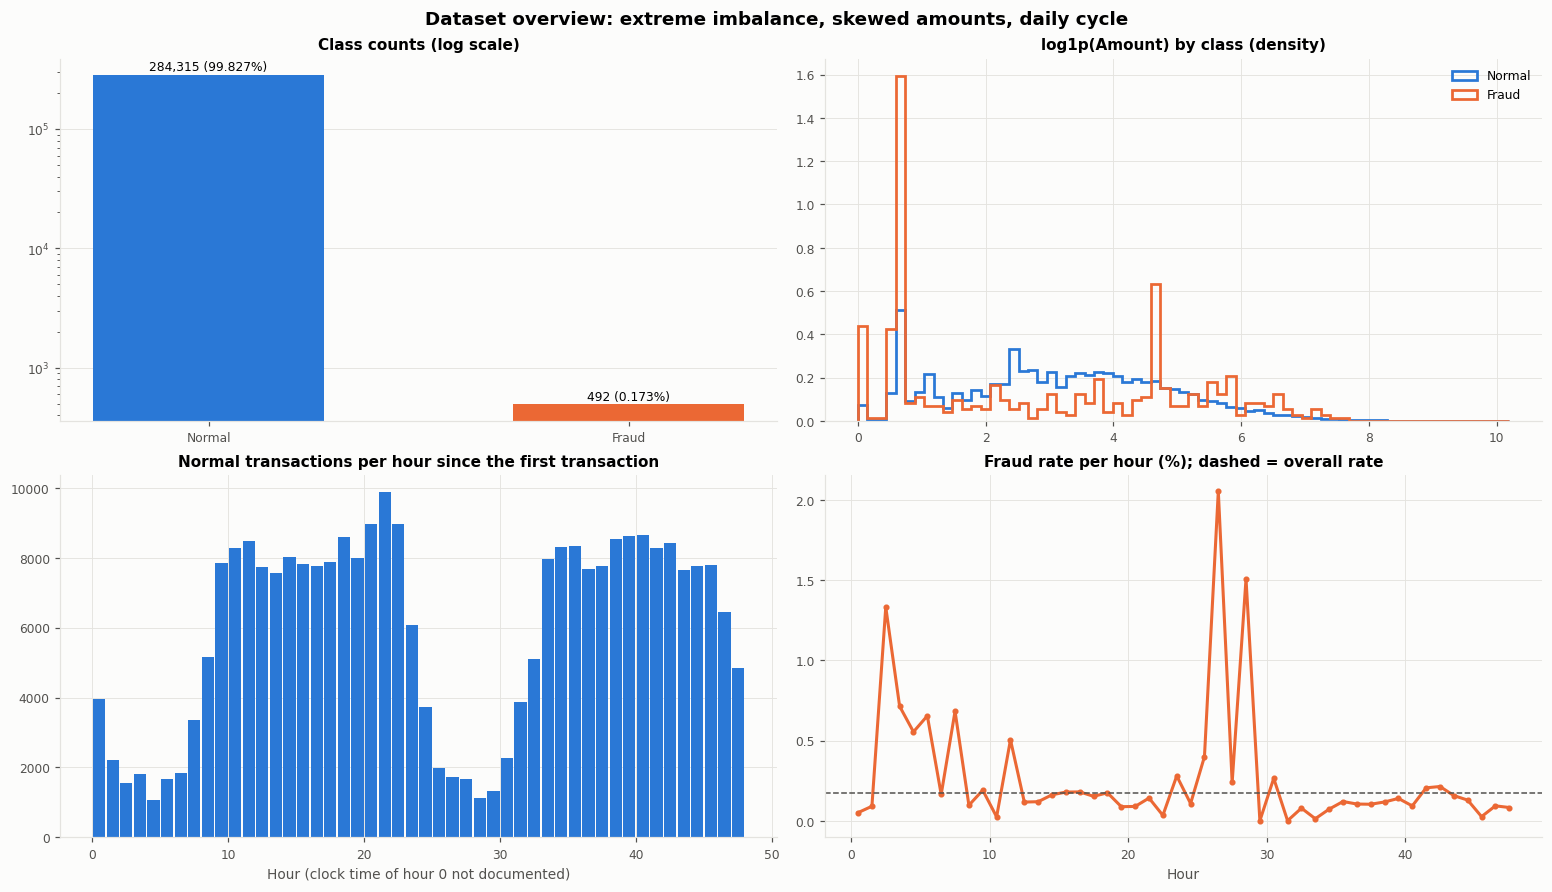

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout="constrained")
counts = df.Class.value_counts().sort_index()
bars = axes[0, 0].bar(["Normal", "Fraud"], counts.values, color=[NORMAL_C, FRAUD_C], width=0.55)
axes[0, 0].set_yscale("log"); axes[0, 0].set_title("Class counts (log scale)"); axes[0, 0].grid(axis="x", visible=False)
for b, n in zip(bars, counts.values):
    axes[0, 0].annotate(f"{n:,} ({100 * n / counts.sum():.3f}%)", (b.get_x() + b.get_width() / 2, n), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
class_hist(axes[0, 1], [np.log1p(df.loc[df.Class == k, "Amount"]) for k in (0, 1)], np.linspace(0, 10.2, 70))
axes[0, 1].set_title("log1p(Amount) by class (density)"); axes[0, 1].legend()
hours = (df.Time // 3600).astype(int)
per_hour = pd.crosstab(hours, df.Class)
axes[1, 0].bar(per_hour.index + 0.5, per_hour[0], width=0.9, color=NORMAL_C)
axes[1, 0].set_title("Normal transactions per hour since the first transaction"); axes[1, 0].set_xlabel("Hour (clock time of hour 0 not documented)")
axes[1, 1].plot(per_hour.index + 0.5, 100 * per_hour[1] / per_hour.sum(axis=1), color=FRAUD_C, linewidth=2, marker="o", markersize=3)
axes[1, 1].axhline(100 * df.Class.mean(), color=TEXT2, linestyle="--", linewidth=1)
axes[1, 1].set_title("Fraud rate per hour (%); dashed = overall rate"); axes[1, 1].set_xlabel("Hour")
fig.suptitle("Dataset overview: extreme imbalance, skewed amounts, daily cycle")
finish(fig, "eda_overview")

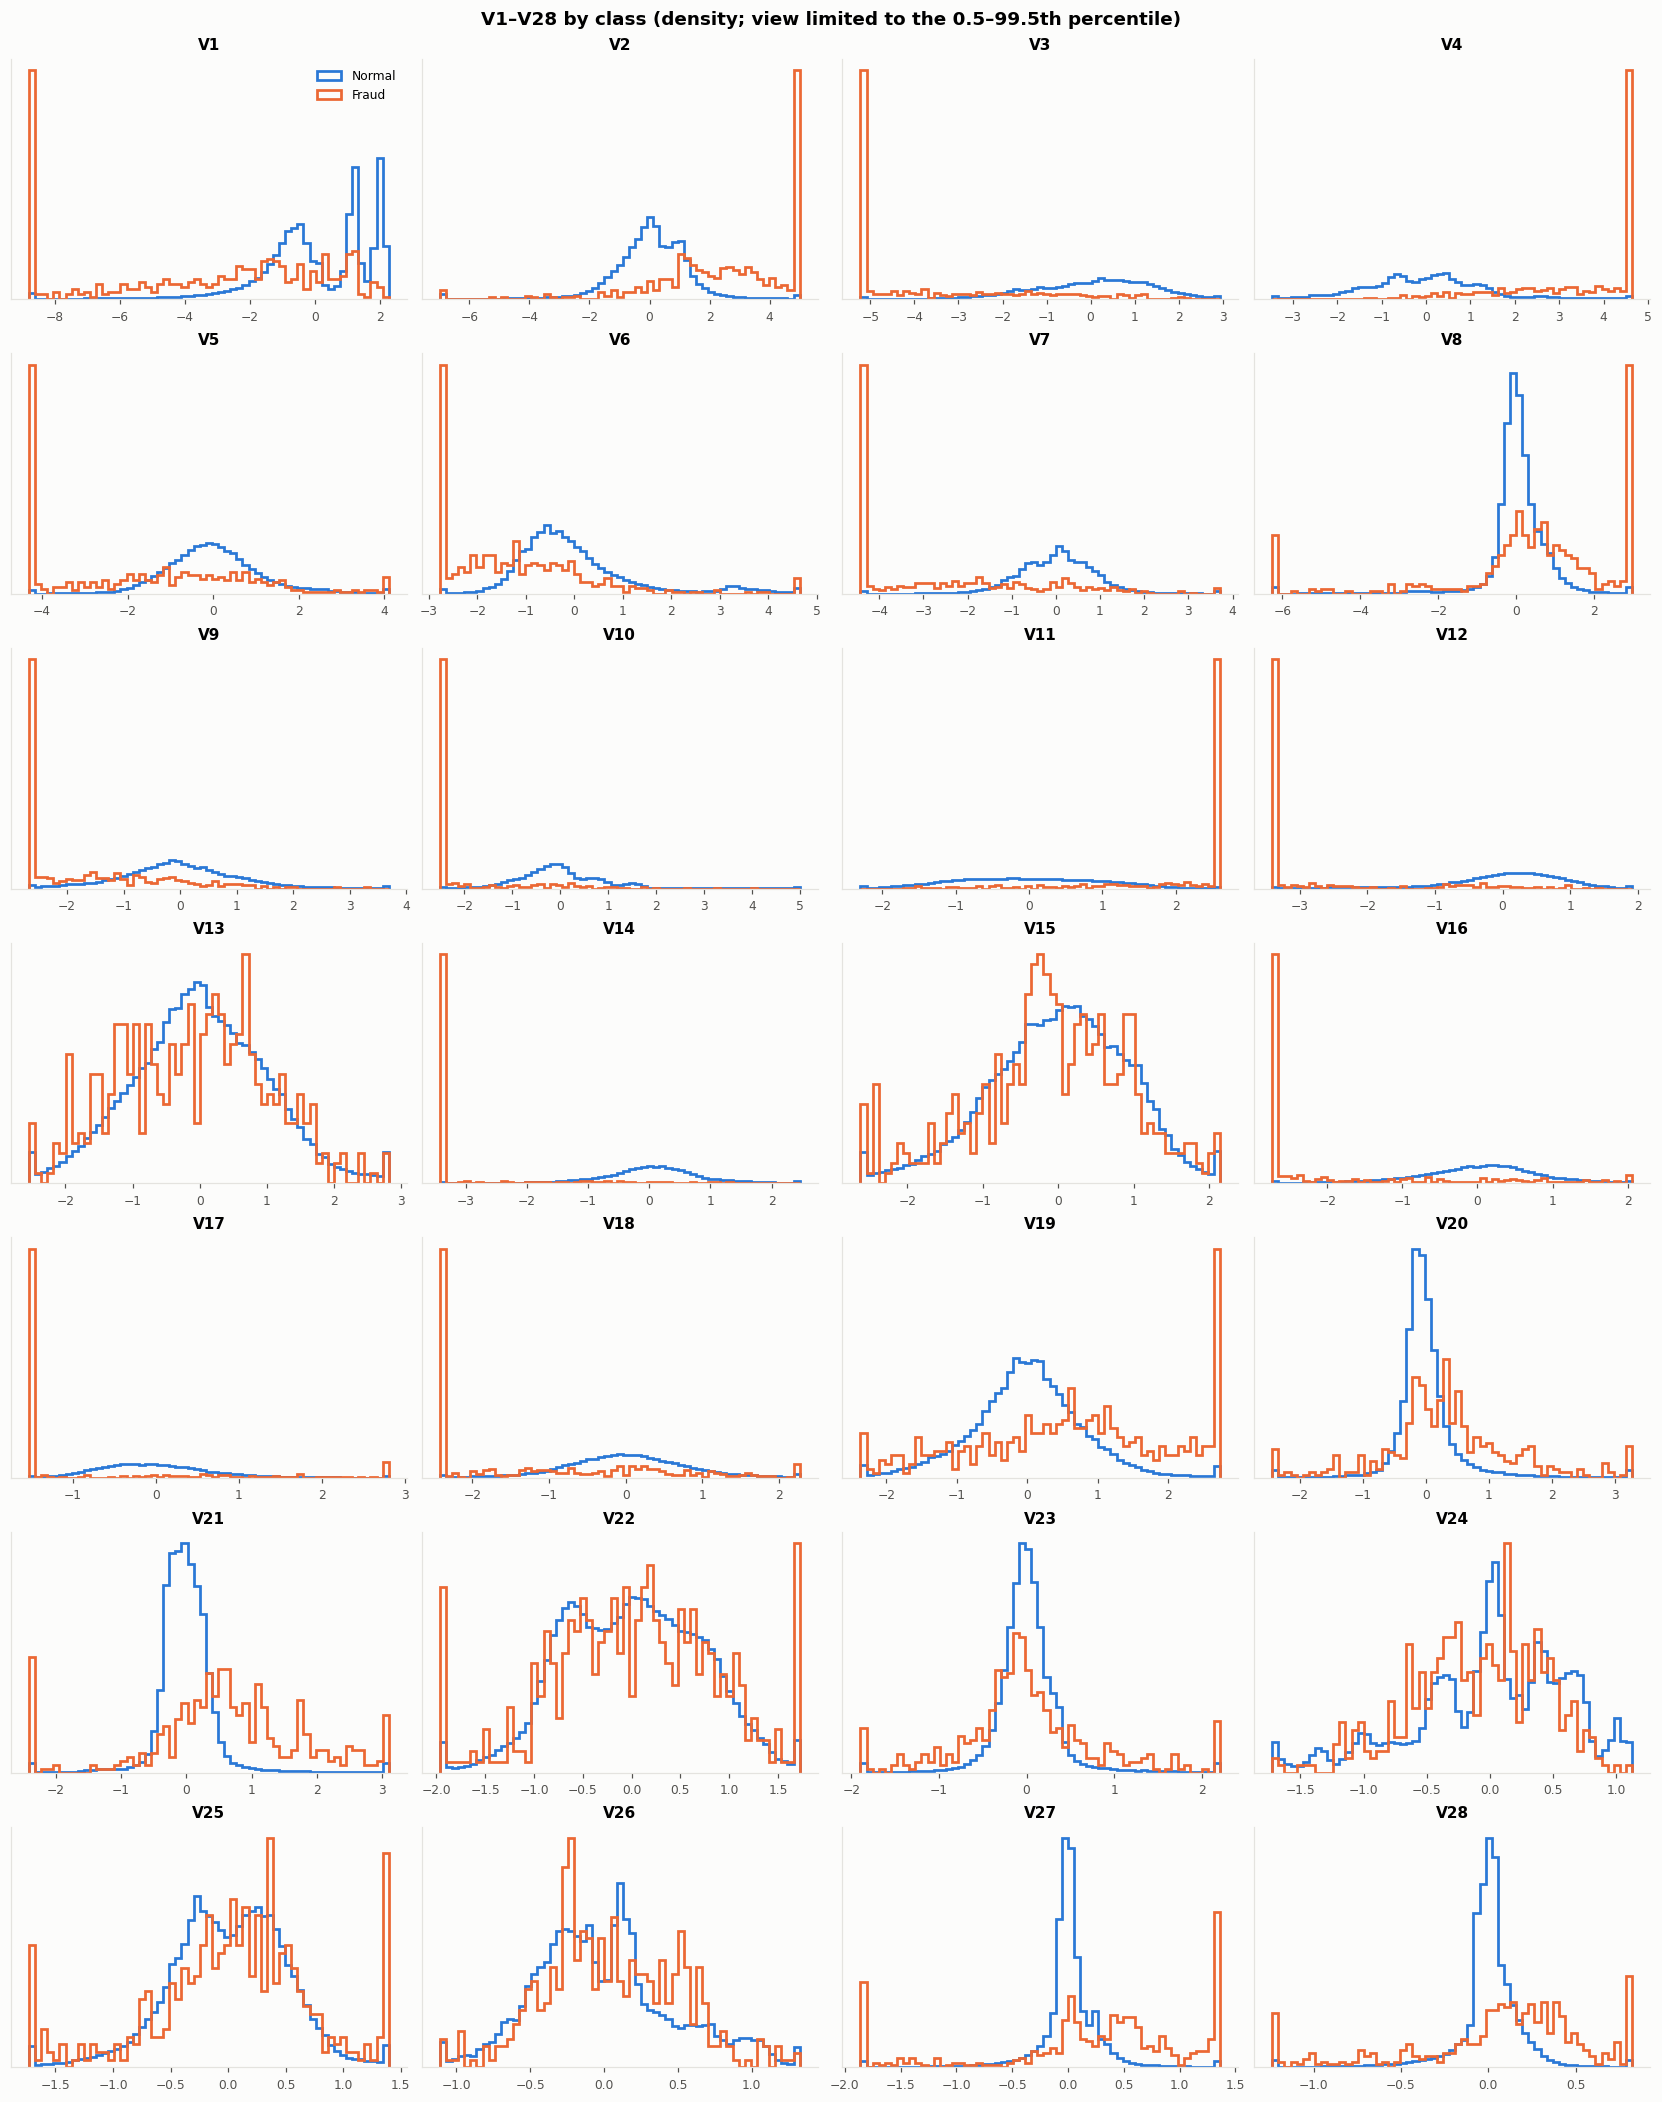

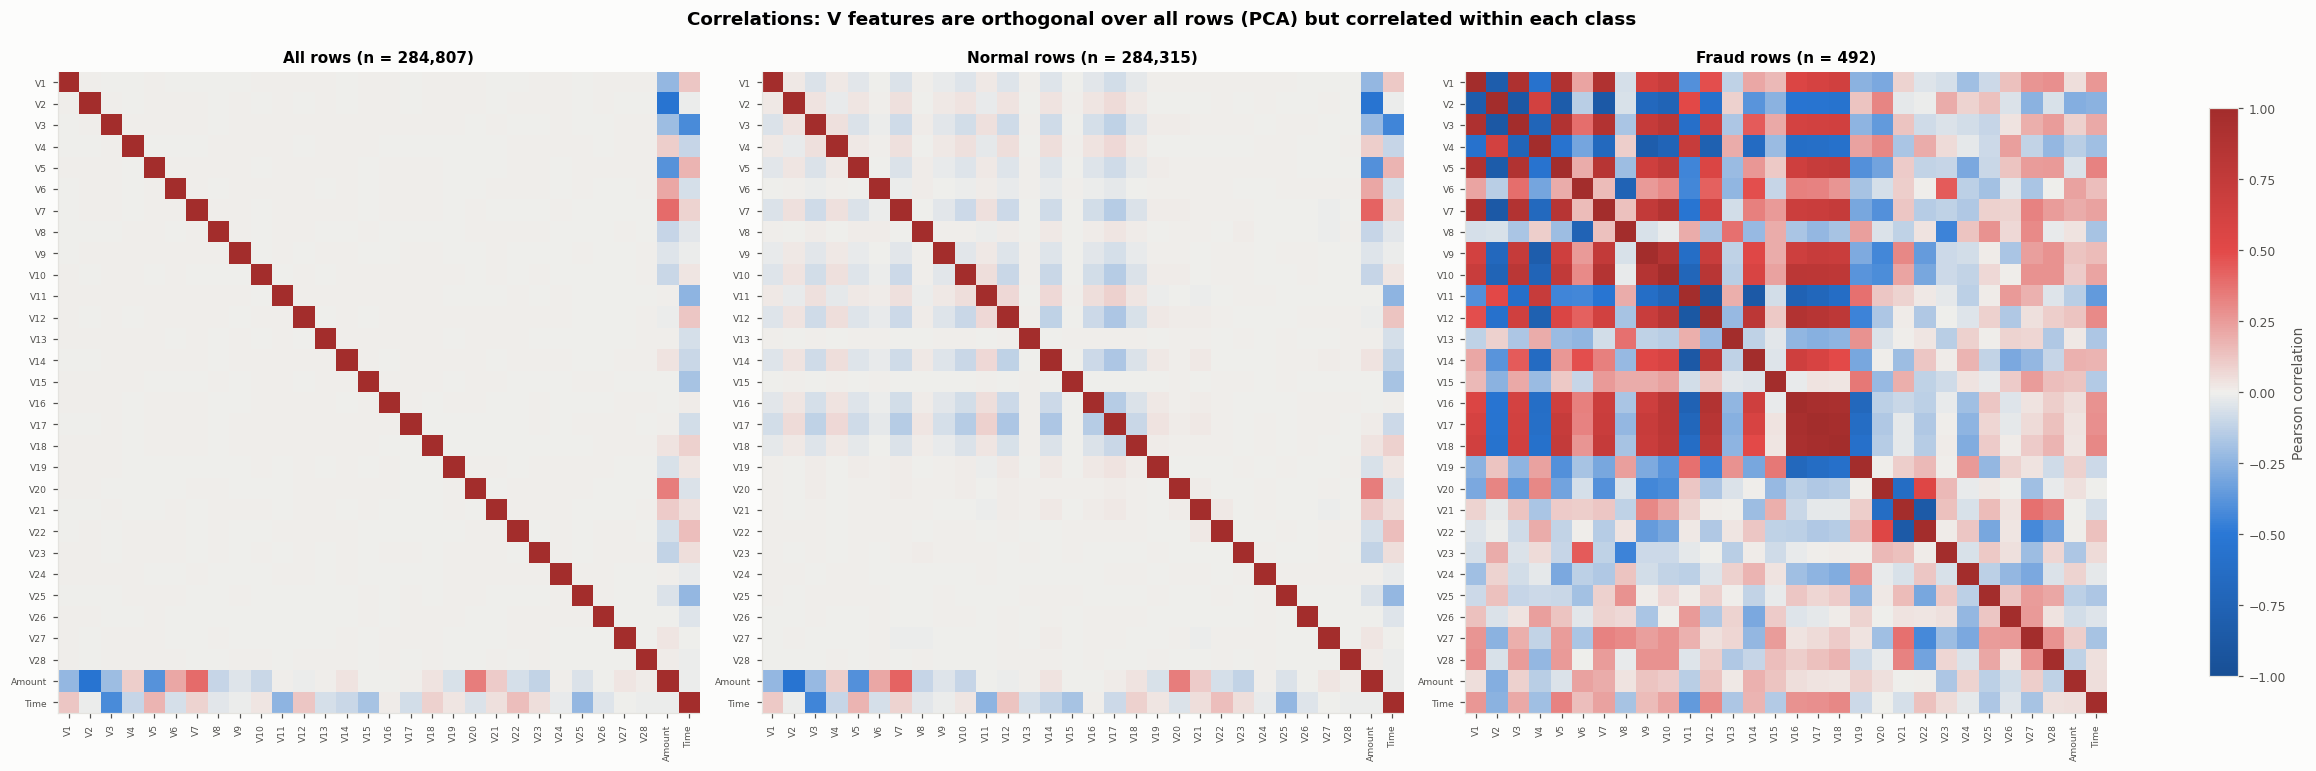

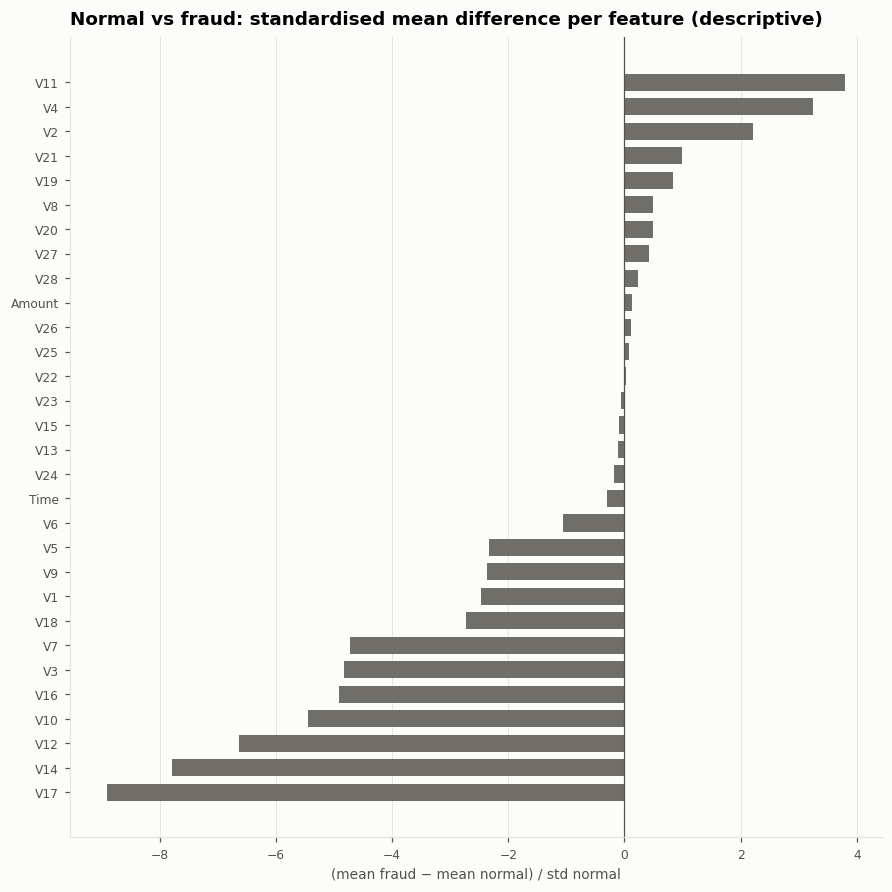

In [9]:
fig, axes = plt.subplots(7, 4, figsize=(15, 19), layout="constrained")
for ax, col in zip(axes.flat, PCA_FEATURES):
    lo, hi = df[col].quantile([0.005, 0.995])
    class_hist(ax, [df.loc[df.Class == k, col].clip(lo, hi) for k in (0, 1)], np.linspace(lo, hi, 60))
    ax.set_title(col); ax.set_yticks([]); ax.grid(visible=False)
axes.flat[0].legend()
fig.suptitle("V1–V28 by class (density; view limited to the 0.5–99.5th percentile)")
finish(fig, "eda_feature_distributions")

fig, axes = plt.subplots(1, 3, figsize=(21, 7), layout="constrained")
cols = [*PCA_FEATURES, "Amount", "Time"]
for ax, (title, frame) in zip(axes, [("All rows", df), ("Normal rows", df[df.Class == 0]), ("Fraud rows", df[df.Class == 1])]):
    im = ax.imshow(frame[cols].corr().to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=6); ax.set_yticks(range(len(cols)), cols, fontsize=6)
    ax.grid(visible=False); ax.set_title(f"{title} (n = {len(frame):,})")
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson correlation")
fig.suptitle("Correlations: V features are orthogonal over all rows (PCA) but correlated within each class")
finish(fig, "eda_correlations")

normal, fraud = df[df.Class == 0], df[df.Class == 1]
smd = ((fraud[cols].mean() - normal[cols].mean()) / normal[cols].std()).sort_values()
fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")
ax.barh(smd.index, smd.values, color=E2_C, height=0.7); ax.axvline(0, color=TEXT2, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("(mean fraud − mean normal) / std normal")
fig.suptitle("Normal vs fraud: standardised mean difference per feature (descriptive)")
finish(fig, "eda_class_comparison")

**EDA findings:**
- **Imbalance:** extreme (see the fraud percentage above), so precision-recall metrics are used.
- **Duplicates:** present, but no feature vector appears with both labels. They are handled by a group-aware split.
- **`Amount`:** heavily skewed, so it is modelled as `log1p(Amount)`.
- **`Time`:** counts seconds since the first transaction and acts like a row index, so it is **not** a model input.
- **V features:** centred but not unit-scaled, and many are heavy-tailed, so all inputs are standardised and extreme values are kept.
- **Class separation:** fraud rows sit far from normal rows on several components, which is the signal a reconstruction-based detector can use.

## 8. Data splitting (leakage-safe)

- **Coverage:** all 284,807 rows are kept and each lands in exactly one split.
- **Duplicate handling:** rows with identical `V1–V28 + Amount` values form a *group*, and a group never spans two splits, so a copy of a training row can never appear in validation or test.
- **Stratification:** groups are shuffled within each class (seed 42) and allocated 70/15/15, which preserves the fraud rate.
- **Label use:** labels are used **only to partition**. E1 trains on normal training rows; E1's threshold is calibrated on normal validation rows; the test split, with both classes, is reserved for the final evaluation. Test labels are locked away until predictions are saved (section 16).

In [10]:
def assign_groups(df: pd.DataFrame) -> np.ndarray:
    return df.groupby(RAW_INPUT_COLUMNS, sort=True).ngroup().to_numpy(dtype=np.int64)

def stratified_group_split(groups: np.ndarray, y: np.ndarray, ratios: dict, seed: int) -> dict:
    if (pd.Series(y).groupby(groups).nunique() > 1).any():
        raise ValueError("A group contains both classes")
    rng = np.random.default_rng(seed)
    split_of_group = {}
    for cls in np.unique(y):
        cls_groups, sizes = np.unique(groups[y == cls], return_counts=True)
        order = rng.permutation(len(cls_groups))
        cls_groups, sizes = cls_groups[order], sizes[order]
        starts = np.concatenate([[0], np.cumsum(sizes)[:-1]])
        n = sizes.sum()
        which = np.where(starts < ratios["train"] * n, 0, np.where(starts < (ratios["train"] + ratios["val"]) * n, 1, 2))
        split_of_group.update(zip(cls_groups.tolist(), which.tolist()))
    row_split = np.array([split_of_group[g] for g in groups.tolist()], dtype=np.int8)
    return {name: np.flatnonzero(row_split == i) for i, name in enumerate(("train", "val", "test"))}

y_all = df["Class"].to_numpy()
GROUPS = assign_groups(df)
SPLITS = stratified_group_split(GROUPS, y_all, CONFIG["split"]["ratios"], CONFIG["split"]["seed"])
PARTS = {
    "e1_train": SPLITS["train"][y_all[SPLITS["train"]] == 0],         # E1: normal training rows only
    "e1_val": SPLITS["val"][y_all[SPLITS["val"]] == 0],               # E1: normal validation rows (early stopping + threshold)
    "e2_train": SPLITS["train"],                                      # E2: all training rows, labels ignored
    "e2_val": SPLITS["val"],                                          # E2: all validation rows, labels ignored
    "test": SPLITS["test"],                                           # final evaluation only
}
partition_table = pd.DataFrame([{"partition": k, "rows": len(v), "normal": int((y_all[v] == 0).sum()), "fraud": int(y_all[v].sum()),
                                 "fraud_pct": 100 * y_all[v].mean()} for k, v in {**SPLITS, **{k: v for k, v in PARTS.items() if k != "test"}}.items()])
partition_table = partition_table.set_index("partition")
partition_table.to_csv(DIRS["metrics"] / "partition_counts.csv")
partition_table.round(4)

,rows,normal,fraud,fraud_pct
partition,,,,
train,199366,199021,345,0.1730
val,42721,42647,74,0.1732
test,42720,42647,73,0.1709
e1_train,199021,199021,0,0.0000
e1_val,42647,42647,0,0.0000
e2_train,199366,199021,345,0.1730
e2_val,42721,42647,74,0.1732


In [11]:
class TestLabelVault:
    """Holds the test labels. They can only be read for an experiment whose test predictions were saved first."""
    def __init__(self, y_test: np.ndarray):
        self._y = y_test.copy()
        self._predictions = {}
        self.events = []
    def log(self, event: str):
        self.events.append({"time_utc": datetime.now(timezone.utc).isoformat(timespec="milliseconds"), "event": event})
    def register_predictions(self, experiment: str, path: Path):
        self._predictions[experiment] = (path, sha256_file(path))
        self.log(f"{experiment}: test predictions saved ({path.name})")
    def reveal(self, experiment: str) -> np.ndarray:
        if experiment not in self._predictions:
            raise RuntimeError("Test labels requested before test predictions were saved")
        path, sha = self._predictions[experiment]
        if sha256_file(path) != sha:
            raise RuntimeError("Prediction file changed after it was saved")
        self.log(f"{experiment}: test labels revealed")
        return self._y.copy()

VAULT = TestLabelVault(y_all[SPLITS["test"]])
VAULT.log("split created; test labels locked")
print({k: len(v) for k, v in SPLITS.items()}, "| total:", sum(len(v) for v in SPLITS.values()))

{'train': 199366, 'val': 42721, 'test': 42720} | total: 284807


## 9. Preprocessing

**Model inputs (29):** `V1–V28` plus `log1p(Amount)`. **`Class` and `Time` are never inputs.**

**Scaling:** standardisation using the mean and population std of the **experiment's own training rows**: normal training rows for E1, all training rows for E2. Validation and test are only *transformed* with those statistics. The transformer can also invert the mapping, which is used to export synthetic data on the original scale.

In [12]:
MODEL_FEATURES = [*PCA_FEATURES, "log1p_Amount"]

class FeatureTransformer:
    def __init__(self):
        self.mean_ = self.scale_ = None
    @staticmethod
    def _engineer(frame: pd.DataFrame) -> np.ndarray:
        out = np.empty((len(frame), 29), dtype=np.float64)
        out[:, :28] = frame[PCA_FEATURES].to_numpy(dtype=np.float64)
        out[:, 28] = np.log1p(frame["Amount"].to_numpy(dtype=np.float64))
        return out
    def fit(self, frame: pd.DataFrame):
        feats = self._engineer(frame[RAW_INPUT_COLUMNS])
        self.mean_, self.scale_ = feats.mean(axis=0), feats.std(axis=0)
        self.n_fit_rows = len(frame)
        return self
    def transform(self, frame: pd.DataFrame, dtype=np.float32) -> np.ndarray:
        return ((self._engineer(frame[RAW_INPUT_COLUMNS]) - self.mean_) / self.scale_).astype(dtype)
    def inverse_transform(self, Z: np.ndarray) -> pd.DataFrame:
        feats = np.asarray(Z, dtype=np.float64) * self.scale_ + self.mean_
        out = pd.DataFrame(feats[:, :28], columns=PCA_FEATURES)
        out["Amount"] = np.round(np.clip(np.expm1(feats[:, 28]), 0.0, None), 2)
        return out
    def to_dict(self):
        return {"feature_names": MODEL_FEATURES, "mean": self.mean_.tolist(), "scale": self.scale_.tolist(), "n_fit_rows": self.n_fit_rows}

TRANSFORMERS = {"e1": FeatureTransformer().fit(df.iloc[PARTS["e1_train"]]), "e2": FeatureTransformer().fit(df.iloc[PARTS["e2_train"]])}
DATA = {}
for exp in ("e1", "e2"):
    tf = TRANSFORMERS[exp]
    DATA[exp] = {"X_train": tf.transform(df.iloc[PARTS[f"{exp}_train"]]), "X_val": tf.transform(df.iloc[PARTS[f"{exp}_val"]]),
                 "X_test": tf.transform(df.iloc[PARTS["test"]])}
    save_json(tf.to_dict(), DIRS["checkpoints"] / f"transformer_{exp}.json")
print({exp: {k: v.shape for k, v in d.items()} for exp, d in DATA.items()})

{'e1': {'X_train': (199021, 29), 'X_val': (42647, 29), 'X_test': (42720, 29)}, 'e2': {'X_train': (199366, 29), 'X_val': (42721, 29), 'X_test': (42720, 29)}}


In [13]:
def leakage_checks() -> pd.DataFrame:
    res = []
    def add(name, ok, detail): res.append({"check": name, "passed": bool(ok), "detail": detail})
    all_idx = np.concatenate(list(SPLITS.values()))
    add("splits_disjoint_and_cover_all_rows", len(all_idx) == len(np.unique(all_idx)) == len(df), f"{len(all_idx):,} rows assigned")
    split_of_row = np.empty(len(df), dtype=np.int8)
    for i, s in enumerate(SPLITS):
        split_of_row[SPLITS[s]] = i
    add("no_duplicate_group_spans_two_splits", (pd.Series(split_of_row).groupby(GROUPS).nunique() == 1).all(), "group-aware split")
    overall = 100 * y_all.mean()
    rates = {s: 100 * y_all[v].mean() for s, v in SPLITS.items()}
    add("fraud_rate_preserved", all(abs(r - overall) <= CONFIG["split"]["stratify_tolerance_pp"] for r in rates.values()),
        ", ".join(f"{s} {r:.4f}%" for s, r in rates.items()))
    add("e1_training_rows_are_all_normal", y_all[PARTS["e1_train"]].sum() == 0, f"{len(PARTS['e1_train']):,} rows, 0 fraud")
    add("e1_calibration_rows_are_all_normal", y_all[PARTS["e1_val"]].sum() == 0, f"{len(PARTS['e1_val']):,} rows, 0 fraud")
    add("test_has_both_classes", 0 < y_all[SPLITS["test"]].sum() < len(SPLITS["test"]), f"{int(y_all[SPLITS['test']].sum())} frauds")
    add("class_and_time_not_in_model_inputs", "Class" not in MODEL_FEATURES and "Time" not in MODEL_FEATURES and all(d["X_train"].shape[1] == 29 for d in DATA.values()),
        "inputs = V1-V28 + log1p(Amount)")
    for exp in ("e1", "e2"):
        feats = FeatureTransformer._engineer(df.iloc[PARTS[f"{exp}_train"]])
        add(f"{exp}_scaler_fitted_on_its_training_rows_only", np.allclose(TRANSFORMERS[exp].mean_, feats.mean(0), atol=1e-12)
            and np.allclose(TRANSFORMERS[exp].scale_, feats.std(0), atol=1e-12), f"{TRANSFORMERS[exp].n_fit_rows:,} rows")
    back = TRANSFORMERS["e1"].inverse_transform(TRANSFORMERS["e1"].transform(df.iloc[SPLITS["test"][:1000]], dtype=np.float64))
    add("inverse_transform_round_trip", np.allclose(back[PCA_FEATURES], df.iloc[SPLITS["test"][:1000]][PCA_FEATURES], atol=1e-9), "V1-V28 recovered")
    return pd.DataFrame(res)

LEAKAGE = leakage_checks()
LEAKAGE.to_csv(DIRS["metrics"] / "leakage_checks.csv", index=False)
assert LEAKAGE["passed"].all(), LEAKAGE[~LEAKAGE["passed"]]
LEAKAGE

,check,passed,detail
0,splits_disjoint_and_cover_all_rows,True,"284,807 rows assigned"
1,no_duplicate_group_spans_two_splits,True,group-aware split
2,fraud_rate_preserved,True,"train 0.1730%, val 0.1732%, test 0.1709%"
3,e1_training_rows_are_all_normal,True,"199,021 rows, 0 fraud"
4,e1_calibration_rows_are_all_normal,True,"42,647 rows, 0 fraud"
5,test_has_both_classes,True,73 frauds
6,class_and_time_not_in_model_inputs,True,inputs = V1-V28 + log1p(Amount)
7,e1_scaler_fitted_on_its_training_rows_only,True,"199,021 rows"
8,e2_scaler_fitted_on_its_training_rows_only,True,"199,366 rows"
9,inverse_transform_round_trip,True,V1-V28 recovered


## 10. VAE architecture

**Generative model:**
- prior $p(z)=\mathcal N(0,I)$
- decoder $p_\theta(x\mid z)=\mathcal N(\hat x_\theta(z), I)$

**Encoder:** $q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}\sigma^2_\phi(x))$. The network outputs $\log\sigma^2$, clamped to $[-10,10]$ for numerical stability.

**ELBO:**
$$\log p_\theta(x)\ \ge\ \mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-\mathrm{KL}(q_\phi(z\mid x)\,\|\,p(z))$$

**Loss** (minimised):
$$\mathcal L(x)=\tfrac12\lVert x-\hat x\rVert^2+\beta\Big(-\tfrac12\textstyle\sum_k(1+\log\sigma_k^2-\mu_k^2-\sigma_k^2)\Big)$$

The first term is an MSE summed over the 29 features, which is the Gaussian negative log-likelihood up to a constant. The second is the closed-form KL. $\beta$ warms up from 0.1 to 1 over 10 epochs to reduce posterior collapse.

**Reparameterization:** $z=\mu+\sigma\odot\varepsilon$, with $\varepsilon\sim\mathcal N(0,I)$, keeps sampling differentiable.

**Network:** 29 → 64 → 32 → (μ, log σ²) in 8 dimensions; decoder 8 → 32 → 64 → 29.
- **LeakyReLU** activations.
- **No batch normalisation**, so generation doesn't depend on batch statistics.
- **Linear output**, because standardised features are unbounded.

The small bottleneck stops the network from simply copying its input, which would reconstruct fraud too.

In [14]:
ACTIVATIONS = {"leaky_relu": lambda: nn.LeakyReLU(0.01), "relu": nn.ReLU, "gelu": nn.GELU}

@dataclass
class VAEConfig:
    input_dim: int = 29
    hidden_dims: list = field(default_factory=lambda: [64, 32])
    latent_dim: int = 8
    activation: str = "leaky_relu"
    logvar_min: float = -10.0
    logvar_max: float = 10.0

def mlp(dims, activation):
    layers = []
    for a, b in zip(dims[:-1], dims[1:]):
        layers += [nn.Linear(a, b), ACTIVATIONS[activation]()]
    return nn.Sequential(*layers)

class Encoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.trunk = mlp([cfg.input_dim, *cfg.hidden_dims], cfg.activation)
        self.mu_head = nn.Linear(cfg.hidden_dims[-1], cfg.latent_dim)
        self.logvar_head = nn.Linear(cfg.hidden_dims[-1], cfg.latent_dim)
    def forward(self, x):
        h = self.trunk(x)
        return self.mu_head(h), self.logvar_head(h).clamp(self.cfg.logvar_min, self.cfg.logvar_max)

class Decoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        hidden = list(reversed(cfg.hidden_dims))
        self.trunk = mlp([cfg.latent_dim, *hidden], cfg.activation)
        self.out = nn.Linear(hidden[-1], cfg.input_dim)
    def forward(self, z):
        return self.out(self.trunk(z))

class VAE(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder, self.decoder = Encoder(cfg), Decoder(cfg)
    def encode(self, x):
        if x.ndim != 2 or x.shape[1] != self.cfg.input_dim:
            raise ValueError(f"expected (n, {self.cfg.input_dim}), got {tuple(x.shape)}")
        if not torch.isfinite(x).all():
            raise ValueError("input contains NaN/Inf")
        return self.encoder(x)
    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn_like(mu) if generator is None else torch.randn(mu.shape, generator=generator, dtype=mu.dtype).to(mu.device)
        return mu + torch.exp(0.5 * logvar) * eps
    def decode(self, z):
        return self.decoder(z)
    def forward(self, x, sample=True, generator=None):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar, generator) if sample else mu
        return self.decode(z), mu, logvar
    @torch.no_grad()
    def sample_prior(self, n, temperature=1.0, generator=None):
        z = torch.randn((n, self.cfg.latent_dim), generator=generator).to(next(self.parameters()).device) * temperature
        return self.decode(z)

def reconstruction_sse(x, recon):
    return 0.5 * (x - recon).pow(2).sum(dim=1)

def kl_divergence(mu, logvar):
    return -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)

def vae_loss(x, recon, mu, logvar, beta):
    rec, kl = reconstruction_sse(x, recon), kl_divergence(mu, logvar)
    total = (rec + beta * kl).mean()
    if not torch.isfinite(total):
        raise FloatingPointError("non-finite loss")
    return {"total": total, "recon": rec.mean(), "kl": kl.mean(), "recon_mse": (x - recon).pow(2).mean()}

MODEL_CFG = VAEConfig(**CONFIG["model"])
_demo = VAE(MODEL_CFG)
print(_demo)
print("parameters:", sum(p.numel() for p in _demo.parameters()))
# forward-pass, shape and gradient checks on a real batch
_x = torch.from_numpy(DATA["e1"]["X_train"][:256])
_recon, _mu, _lv = _demo(_x)
_loss = vae_loss(_x, _recon, _mu, _lv, 1.0)["total"]
_loss.backward()
assert _recon.shape == (256, 29) and _mu.shape == _lv.shape == (256, 8)
assert all(p.grad is not None and p.grad.abs().sum() > 0 for p in _demo.parameters()), "a parameter received no gradient"
assert abs(kl_divergence(torch.zeros(1, 8), torch.zeros(1, 8)).item()) < 1e-7
print("forward/shape/gradient checks passed")
del _demo, _x, _recon, _mu, _lv, _loss

VAE(
  (encoder): Encoder(
    (trunk): Sequential(
      (0): Linear(in_features=29, out_features=64, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=64, out_features=32, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
    )
    (mu_head): Linear(in_features=32, out_features=8, bias=True)
    (logvar_head): Linear(in_features=32, out_features=8, bias=True)
  )
  (decoder): Decoder(
    (trunk): Sequential(
      (0): Linear(in_features=8, out_features=32, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=32, out_features=64, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
    )
    (out): Linear(in_features=64, out_features=29, bias=True)
  )
)
parameters: 8813
forward/shape/gradient checks passed


## 11. Model training (E1, primary: normal transactions only)

**Training loop:**
- Adam, batch 512, gradient clipping at norm 5.
- Seeded single-process DataLoaders, so runs are reproducible.
- KL warm-up over the first 10 epochs.

**Early stopping:** monitors the validation negative ELBO at β = 1, computed with fixed noise, once warm-up has finished. Patience is 10 epochs, and the best epoch's weights are kept.

**Seeds and outputs:** 5 seeds are trained. Each saves a checkpoint, its training history and a threshold, all calibrated on validation data only.

In [15]:
def make_loader(X, batch_size, seed):
    return DataLoader(TensorDataset(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))), batch_size=batch_size,
                      shuffle=True, generator=torch.Generator().manual_seed(seed), num_workers=0)

@torch.no_grad()
def validation_loss(model, X, beta, noise_seed, batch_size=8192):
    model.eval()
    g = torch.Generator().manual_seed(noise_seed)
    sums = {"recon": 0.0, "kl": 0.0, "recon_mse_det": 0.0}
    for start in range(0, len(X), batch_size):
        x = torch.from_numpy(X[start:start + batch_size]).to(DEVICE)
        recon, mu, logvar = model(x, sample=True, generator=g)
        sums["recon"] += reconstruction_sse(x, recon).sum().item()
        sums["kl"] += kl_divergence(mu, logvar).sum().item()
        sums["recon_mse_det"] += (x - model.decode(mu)).pow(2).mean(dim=1).sum().item()
    out = {k: v / len(X) for k, v in sums.items()}
    out["total"] = out["recon"] + beta * out["kl"]
    return out

def train_vae(X_train, X_val, seed, log_every=50):
    tc = CONFIG["training"]
    torch.manual_seed(seed)
    model = VAE(MODEL_CFG).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=tc["learning_rate"], weight_decay=tc["weight_decay"])
    loader = make_loader(X_train, tc["batch_size"], seed)
    history, best_state, best_epoch, best_val, stale = [], None, 0, float("inf"), 0
    start = time.perf_counter()
    for epoch in range(1, tc["max_epochs"] + 1):
        beta = tc["beta"] * min(1.0, epoch / tc["kl_warmup_epochs"])
        model.train()
        sums = {"total": 0.0, "recon": 0.0, "kl": 0.0}
        for (x,) in loader:
            x = x.to(DEVICE)
            losses = vae_loss(x, *model(x), beta)
            opt.zero_grad(set_to_none=True)
            losses["total"].backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), tc["grad_clip_norm"])
            opt.step()
            for k in sums:
                sums[k] += losses[k].item() * len(x)
        val = validation_loss(model, X_val, tc["beta"], tc["val_noise_seed"])
        warm = epoch >= tc["kl_warmup_epochs"]
        improved = warm and val["total"] < best_val - 1e-6
        if improved:
            best_val, best_epoch, best_state, stale = val["total"], epoch, copy.deepcopy(model.state_dict()), 0
        elif warm:
            stale += 1
        history.append({"epoch": epoch, "beta": beta, **{f"train_{k}": v / len(X_train) for k, v in sums.items()},
                        **{f"val_{k}": v for k, v in val.items()}})
        if epoch % log_every == 0:
            print(f"    epoch {epoch:3d}  train {history[-1]['train_total']:.4f}  val {val['total']:.4f}")
        if warm and stale >= tc["early_stopping_patience"]:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch, time.perf_counter() - start

@torch.no_grad()
def recon_mse(model, X, batch_size=8192):
    model.eval()
    out = []
    for start in range(0, len(X), batch_size):
        x = torch.from_numpy(np.ascontiguousarray(X[start:start + batch_size])).to(DEVICE)
        out.append((x - model(x, sample=False)[0]).pow(2).mean(dim=1).double().cpu())
    return torch.cat(out).numpy()

def train_experiment(exp: str) -> dict:
    """Train every seed of one experiment, calibrate its threshold on validation scores and save artefacts."""
    runs = {}
    for seed in CONFIG["seeds"]:
        print(f"[{exp} seed {seed}] training on {len(DATA[exp]['X_train']):,} rows on {DEVICE}")
        set_seed(seed)
        model, history, best_epoch, runtime = train_vae(DATA[exp]["X_train"], DATA[exp]["X_val"], seed)
        val_scores = recon_mse(model, DATA[exp]["X_val"])
        tau = float(np.percentile(val_scores, CONFIG["threshold_percentile"]))   # labels never used
        ckpt = DIRS["checkpoints"] / f"vae_{exp}_seed{seed}.pt"
        torch.save({"model_state": model.state_dict(), "model_config": asdict(MODEL_CFG), "experiment": exp, "seed": seed,
                    "best_epoch": best_epoch, "threshold": tau}, ckpt)
        history.to_csv(DIRS["metrics"] / f"history_{exp}_seed{seed}.csv", index=False)
        runs[seed] = {"model": model, "history": history, "best_epoch": best_epoch, "epochs_run": int(history.epoch.max()),
                      "runtime_s": runtime, "val_scores": val_scores, "threshold": tau, "checkpoint": ckpt}
        print(f"[{exp} seed {seed}] best epoch {best_epoch}/{runs[seed]['epochs_run']}, {runtime:.0f}s, threshold {tau:.4f}")
    return runs

RUNS = {"e1": train_experiment("e1")}

[e1 seed 0] training on 199,021 rows on cpu
    epoch  50  train 10.5233  val 10.5205
    epoch 100  train 10.3419  val 10.3579
    epoch 150  train 10.2649  val 10.2749
[e1 seed 0] best epoch 178/188, 73s, threshold 1.2292
[e1 seed 1] training on 199,021 rows on cpu
    epoch  50  train 10.4887  val 10.5043
    epoch 100  train 10.3749  val 10.3809
[e1 seed 1] best epoch 103/113, 44s, threshold 1.2303
[e1 seed 2] training on 199,021 rows on cpu
    epoch  50  train 10.5713  val 10.5796
    epoch 100  train 10.4332  val 10.4459
    epoch 150  train 10.3487  val 10.3741
[e1 seed 2] best epoch 142/152, 59s, threshold 1.2839
[e1 seed 3] training on 199,021 rows on cpu
    epoch  50  train 10.5610  val 10.5685
    epoch 100  train 10.3969  val 10.4038
    epoch 150  train 10.3279  val 10.3401
    epoch 200  train 10.2925  val 10.3002
    epoch 250  train 10.2516  val 10.2853
[e1 seed 3] best epoch 246/256, 100s, threshold 1.2342
[e1 seed 4] training on 199,021 rows on cpu
    epoch  50  tr

## 12. Training evaluation and loss plots

,best_epoch,epochs_run,runtime_s,best_val_neg_elbo,val_recon_mse,threshold
seed,,,,,,
0,178,188,72.9,10.2479,0.4094,1.2292
1,103,113,44.4,10.3653,0.4080,1.2303
2,142,152,59.0,10.3636,0.4137,1.2839
3,246,256,99.6,10.2681,0.4048,1.2342
4,170,180,70.0,10.3784,0.4044,1.2178


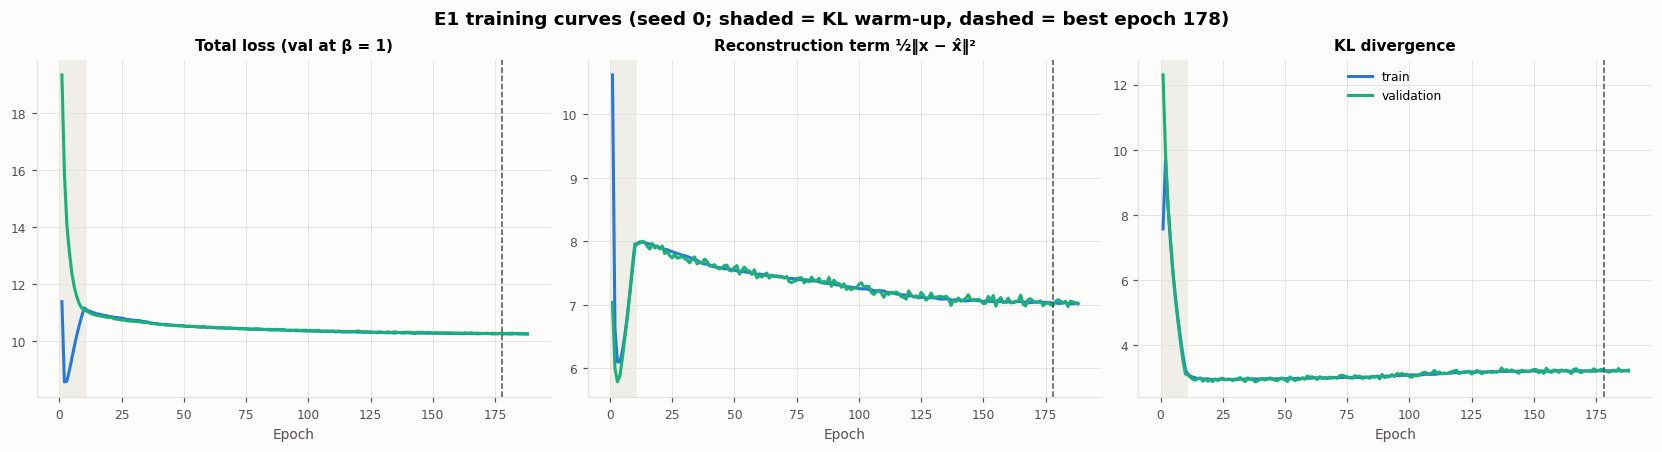

In [16]:
def training_table(exp):
    return pd.DataFrame([{"seed": s, "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"], "runtime_s": round(r["runtime_s"], 1),
                          "best_val_neg_elbo": r["history"].loc[r["history"].epoch == r["best_epoch"], "val_total"].iloc[0],
                          "val_recon_mse": r["history"].loc[r["history"].epoch == r["best_epoch"], "val_recon_mse_det"].iloc[0],
                          "threshold": r["threshold"]} for s, r in RUNS[exp].items()]).set_index("seed")

def plot_training(exp, seed):
    r = RUNS[exp][seed]
    h = r["history"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    for ax, key, title in ((axes[0], "total", "Total loss (val at β = 1)"), (axes[1], "recon", "Reconstruction term ½‖x − x̂‖²"), (axes[2], "kl", "KL divergence")):
        ax.plot(h.epoch, h[f"train_{key}"], color=NORMAL_C, linewidth=2, label="train")
        ax.plot(h.epoch, h[f"val_{key}"], color=SYNTH_C, linewidth=2, label="validation")
        ax.axvspan(0.5, CONFIG["training"]["kl_warmup_epochs"] + 0.5, color="#efeee9", zorder=0)
        ax.axvline(r["best_epoch"], color=TEXT2, linestyle="--", linewidth=1)
        ax.set_title(title); ax.set_xlabel("Epoch")
    axes[2].legend()
    fig.suptitle(f"{exp.upper()} training curves (seed {seed}; shaded = KL warm-up, dashed = best epoch {r['best_epoch']})")
    finish(fig, f"training_curves_{exp}_seed{seed}")

TRAINING_E1 = training_table("e1")
TRAINING_E1.to_csv(DIRS["metrics"] / "training_summary_e1.csv")
display(TRAINING_E1.round(4))
plot_training("e1", CONFIG["headline_seed"])

## 13. Threshold calibration (no fraud labels, no test data)

τ is the **99th percentile of reconstruction error on the 42,647 normal validation transactions**. About 1% of normal traffic is flagged, which is an explicit alert budget. Fraud labels play no part, and neither do the test set or the validation frauds. Other percentiles appear later only as a sensitivity analysis.

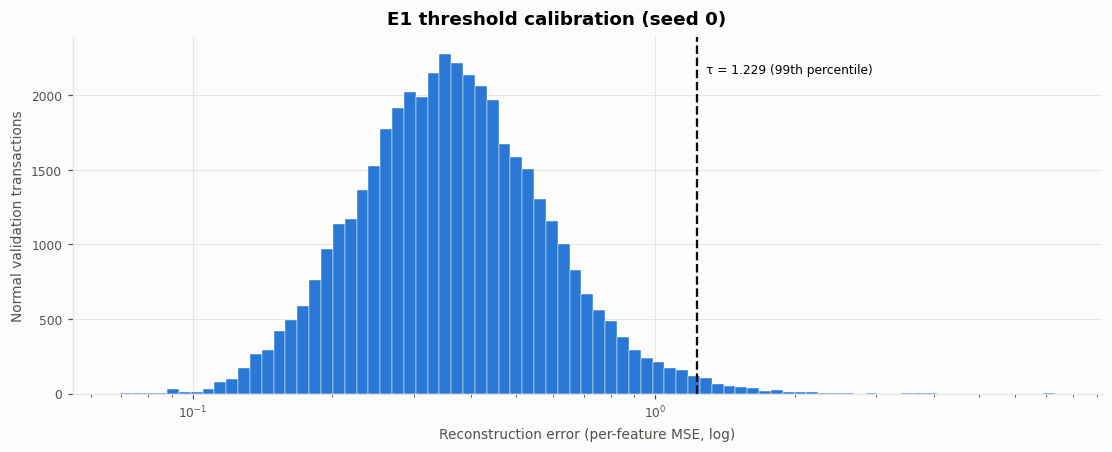

,E1 headline seed
method,99th percentile of reconstruction error on nor...
rows,42647
threshold,1.229167
validation_flag_rate,0.010012
fraud_labels_used,False


In [17]:
hs = CONFIG["headline_seed"]
r = RUNS["e1"][hs]
THRESHOLD_RECORD = {"method": "99th percentile of reconstruction error on normal validation rows", "rows": len(r["val_scores"]),
                    "threshold": r["threshold"], "validation_flag_rate": float(np.mean(r["val_scores"] > r["threshold"])), "fraud_labels_used": False,
                    "thresholds_all_seeds": {s: RUNS["e1"][s]["threshold"] for s in CONFIG["seeds"]}}
save_json(THRESHOLD_RECORD, DIRS["metrics"] / "threshold_calibration_e1.json")
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
bins = np.logspace(np.log10(r["val_scores"].min()), np.log10(r["val_scores"].max()), 80)
ax.hist(r["val_scores"], bins=bins, color=NORMAL_C, edgecolor=SURFACE, linewidth=0.3)
ax.set_xscale("log"); ax.axvline(r["threshold"], color=TEXT, linestyle="--", linewidth=1.5)
ax.annotate(f"τ = {r['threshold']:.3f} (99th percentile)", (r["threshold"], ax.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords="offset points", fontsize=8)
ax.set_xlabel("Reconstruction error (per-feature MSE, log)"); ax.set_ylabel("Normal validation transactions")
fig.suptitle(f"E1 threshold calibration (seed {hs})")
finish(fig, "threshold_calibration_e1")
pd.Series({k: v for k, v in THRESHOLD_RECORD.items() if k != "thresholds_all_seeds"}).to_frame("E1 headline seed")

## 14. Synthetic sample generation (core Generative AI component)

The trained E1 decoder turns random latent vectors into new transaction feature vectors:

1. Sample $z\sim\mathcal N(0,I)$ from the prior.
2. Decode to $\hat x(z)$.
3. Apply the fitted inverse transformation.
4. Export to CSV, with **no fraud label**.

There are two samplers, reported side by side. Neither is chosen using evaluation results.
- **Decoder mean (primary):** $x=\hat x(z)$.
- **Decoder mean + fitted noise (variant):** $x=\hat x(z)+\varepsilon$, with $\varepsilon\sim\mathcal N(0,\operatorname{diag}\sigma^2)$. Here $\sigma$ is the decoder's noise level, estimated from **training** residuals, so this draws a full sample from $p(x\mid z)$.

> Generated rows are vectors in the dataset's **anonymised PCA feature space** (`V1–V28`) plus `Amount`. They are **not** interpretable or verified real-world transactions.

In [18]:
@torch.no_grad()
def fit_decoder_noise_std(model, X_train, seed, batch_size=8192):
    g = torch.Generator().manual_seed(seed)
    sq = torch.zeros(model.cfg.input_dim, dtype=torch.float64)
    for start in range(0, len(X_train), batch_size):
        x = torch.from_numpy(np.ascontiguousarray(X_train[start:start + batch_size], dtype=np.float32)).to(DEVICE)
        sq += (x - model(x, sample=True, generator=g)[0]).pow(2).sum(dim=0).double().cpu()
    return np.sqrt((sq / len(X_train)).numpy())

@torch.no_grad()
def generate(model, n, seed, temperature=1.0, noise_std=None, batch_size=8192):
    """New samples in standardised space: decode z ~ N(0, temperature^2 I), optionally add decoder noise."""
    g = torch.Generator().manual_seed(seed)
    Z = np.concatenate([model.sample_prior(min(batch_size, n - s), temperature, g).double().cpu().numpy() for s in range(0, n, batch_size)])
    if noise_std is not None:
        Z = Z + np.random.default_rng(seed + 1).normal(size=Z.shape) * noise_std[None, :]
    assert np.isfinite(Z).all()
    return Z

GEN = CONFIG["generation"]
gen_model = RUNS["e1"][hs]["model"]
TF1 = TRANSFORMERS["e1"]
real_ref = df.iloc[PARTS["e1_val"]][RAW_INPUT_COLUMNS].reset_index(drop=True)   # held-out normal rows (validation)
N_SYNTH = len(real_ref)
NOISE_STD = fit_decoder_noise_std(gen_model, DATA["e1"]["X_train"], GEN["seed"])
SYNTHETIC = {}
for name, noise in (("decoder_mean", None), ("decoder_mean_plus_noise", NOISE_STD)):
    synth = TF1.inverse_transform(generate(gen_model, N_SYNTH, GEN["seed"], noise_std=noise))
    path = DIRS["synthetic"] / f"synthetic_{name}_n{N_SYNTH}.csv"
    synth.to_csv(path, index=False, float_format="%.6f")
    SYNTHETIC[name] = {"data": synth, "path": path}
save_json({"model": f"E1 seed {hs}", "sampling_seed": GEN["seed"], "n": N_SYNTH, "noise_std_fitted_on_train": NOISE_STD.tolist(),
           "disclaimer": "Vectors in anonymised PCA feature space; not real or interpretable transactions; no fraud label."},
          DIRS["synthetic"] / "synthetic_metadata.json")
print({k: f"{v['path']} ({len(v['data']):,} rows)" for k, v in SYNTHETIC.items()})
SYNTHETIC["decoder_mean"]["data"].head()

{'decoder_mean': 'vae_outputs/synthetic/synthetic_decoder_mean_n42647.csv (42,647 rows)', 'decoder_mean_plus_noise': 'vae_outputs/synthetic/synthetic_decoder_mean_plus_noise_n42647.csv (42,647 rows)'}


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-0.570534,0.963562,-0.475761,-0.210229,0.811079,-0.809810,0.963391,0.004342,-0.369325,-0.049426,-0.306794,0.103734,-0.266272,0.397107,-0.284170,-0.180824,-0.298262,0.084878,0.242921,-0.099480,0.156861,0.572279,-0.044682,0.012823,-0.049934,0.107435,-0.013975,0.035878,8.29
1,-0.788570,0.638603,0.482027,-0.319478,0.259261,-0.464990,0.402383,0.133458,-0.001989,-0.393629,-0.136785,0.202914,-0.167768,-0.059175,0.082045,0.194514,-0.301856,0.199189,-0.054006,-0.086362,0.034761,0.118569,-0.058399,-0.050510,-0.109417,-0.030275,0.012114,0.005360,14.63
2,-0.769845,0.565710,0.587134,0.303227,-0.135753,-0.114813,0.150409,0.218527,0.244188,-0.537204,-0.121107,0.332615,-0.195155,-0.798650,-0.531203,0.169635,0.394001,0.131319,0.036031,-0.146217,-0.030031,-0.041532,-0.056378,-0.062339,-0.070620,0.119689,-0.093323,-0.035495,21.89
3,-0.388650,0.803615,0.672496,0.513331,0.407454,-0.324214,0.427837,0.086862,-0.357354,-0.118746,-0.160368,0.172334,-0.171203,0.142415,0.094443,0.066944,-0.344012,0.120931,-0.020194,-0.051612,0.070088,0.181024,-0.106181,-0.031866,-0.034299,-0.156355,0.057864,0.049763,9.82
4,0.056795,0.387190,0.604549,0.333800,-0.052828,-0.296769,0.182354,0.100742,0.039141,-0.290273,-0.034081,0.320702,-0.177605,0.008971,0.204905,0.103947,-0.206608,0.029719,0.074967,-0.055594,-0.014156,-0.012493,-0.043662,-0.000103,0.004346,-0.010599,0.015065,0.014341,18.75


## 15. Synthetic-data quality evaluation

The real reference is the **normal validation transactions**. They were never used for training, only for early stopping and the threshold, and using them keeps every test label locked until section 16. A *real vs real* comparison (normal training sample vs reference) gives the noise floor.

**Metrics:**
- per-feature KS statistic and Wasserstein-1 distance;
- mean and std ratios;
- correlation-matrix difference;
- PCA overlay;
- classifier two-sample test (ROC-AUC 0.5 means indistinguishable);
- validity;
- memorisation (distance to the closest training row).

**Note:** the *linear* (logistic) two-sample test is unstable on these heavy-tailed features. Its value depends on which rare extreme rows are in the reference sample (decoder mean: about 0.75 against validation rows, about 0.58 against test rows). The gradient-boosting test is stable and is the one to rely on.

In [19]:
def nearest_distance(queries, reference, chunk=512):
    ref_sq = (reference ** 2).sum(1)
    out = np.empty(len(queries))
    for s in range(0, len(queries), chunk):
        q = queries[s:s + chunk]
        out[s:s + chunk] = np.sqrt(np.maximum(((q ** 2).sum(1)[:, None] + ref_sq[None] - 2 * q @ reference.T).min(1), 0))
    return out

def c2st(real_z, synth_z, n, seed):
    rng = np.random.default_rng(seed)
    r = real_z[rng.choice(len(real_z), min(n, len(real_z)), replace=False)]
    s = synth_z[rng.choice(len(synth_z), min(n, len(synth_z)), replace=False)]
    X, yy = np.vstack([r, s]), np.r_[np.zeros(len(r)), np.ones(len(s))]
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    return {name: float(cross_val_score(clf, X, yy, cv=cv, scoring="roc_auc").mean())
            for name, clf in {"logistic": LogisticRegression(max_iter=2000), "gradient_boosting": HistGradientBoostingClassifier(random_state=seed)}.items()}

def quality_report(real: pd.DataFrame, synth: pd.DataFrame, seed: int) -> dict:
    rz, sz, tz = TF1.transform(real, np.float64), TF1.transform(synth, np.float64), DATA["e1"]["X_train"].astype(np.float64)
    ks = [ks_2samp(rz[:, j], sz[:, j]).statistic for j in range(29)]
    w1 = [wasserstein_distance(rz[:, j], sz[:, j]) for j in range(29)]
    cr, cs = real.corr().to_numpy(), synth.corr().to_numpy()
    rng = np.random.default_rng(seed)
    d_syn = nearest_distance(sz[rng.choice(len(sz), GEN["dcr_samples"], replace=False)], tz)
    d_real = nearest_distance(rz[rng.choice(len(rz), GEN["dcr_samples"], replace=False)], tz)
    q = lambda f, a, b: (f.quantile(b) - f.quantile(a))
    return {"valid_pct": 100 * float((np.isfinite(synth.to_numpy()).all(1) & (synth.Amount >= 0)).mean()),
            "mean_ks": float(np.mean(ks)), "mean_w1": float(np.mean(w1)),
            "mean_abs_mean_diff_std_units": float(((synth[PCA_FEATURES].mean() - real[PCA_FEATURES].mean()).abs() / real[PCA_FEATURES].std()).mean()),
            "std_ratio_V": float((synth[PCA_FEATURES].std() / real[PCA_FEATURES].std()).mean()),
            "tail_width_ratio": float((q(synth[PCA_FEATURES], .001, .999) / q(real[PCA_FEATURES], .001, .999)).median()),
            "corr_frobenius_diff": float(np.linalg.norm(cs - cr)),
            "amount_v2_corr_real": float(real.Amount.corr(real.V2)), "amount_v2_corr_synth": float(synth.Amount.corr(synth.V2)),
            **{f"c2st_{k}": v for k, v in c2st(rz, sz, GEN["c2st_samples"], seed).items()},
            "dcr_median_synth": float(np.median(d_syn)), "dcr_median_real_holdout": float(np.median(d_real)),
            "exact_copies_of_training_rows": int((d_syn < 1e-6).sum()), "per_feature_ks": dict(zip(MODEL_FEATURES, np.round(ks, 4)))}

QUALITY = {name: quality_report(real_ref, v["data"], GEN["seed"]) for name, v in SYNTHETIC.items()}
_ref = df.iloc[PARTS["e1_train"]].sample(N_SYNTH, random_state=GEN["seed"])[RAW_INPUT_COLUMNS].reset_index(drop=True)
QUALITY["real_vs_real_reference"] = quality_report(real_ref, _ref, GEN["seed"])
TEMPERATURES = {t: float((TF1.inverse_transform(generate(gen_model, N_SYNTH, GEN["seed"], t))[PCA_FEATURES].std() / real_ref[PCA_FEATURES].std()).mean())
                for t in GEN["temperatures"]}
quality_table = pd.DataFrame({k: {m: v for m, v in q.items() if m != "per_feature_ks"} for k, q in QUALITY.items()}).T
quality_table.to_csv(DIRS["metrics"] / "synthetic_quality.csv")
save_json({"quality": QUALITY, "std_ratio_by_temperature": TEMPERATURES}, DIRS["metrics"] / "synthetic_quality.json")
print("Std ratio by sampling temperature (decoder mean):", {k: round(v, 3) for k, v in TEMPERATURES.items()})
quality_table.round(4)

Std ratio by sampling temperature (decoder mean): {1.0: 0.496, 0.8: 0.322, 0.5: 0.153}


,valid_pct,mean_ks,mean_w1,mean_abs_mean_diff_std_units,std_ratio_V,tail_width_ratio,corr_frobenius_diff,amount_v2_corr_real,amount_v2_corr_synth,c2st_logistic,c2st_gradient_boosting,dcr_median_synth,dcr_median_real_holdout,exact_copies_of_training_rows
decoder_mean,100.0,0.2211,0.3738,0.0316,0.4961,0.5799,3.7286,-0.5491,-0.5572,0.7750,0.9999,1.8906,0.9206,0.0
decoder_mean_plus_noise,100.0,0.0532,0.0952,0.0306,0.8477,0.7954,1.6851,-0.5491,-0.1722,0.5539,0.9903,3.1006,0.9206,0.0
real_vs_real_reference,100.0,0.0061,0.0100,0.0055,0.9976,0.9989,0.6625,-0.5491,-0.5544,0.4970,0.4978,0.0000,0.9206,5000.0


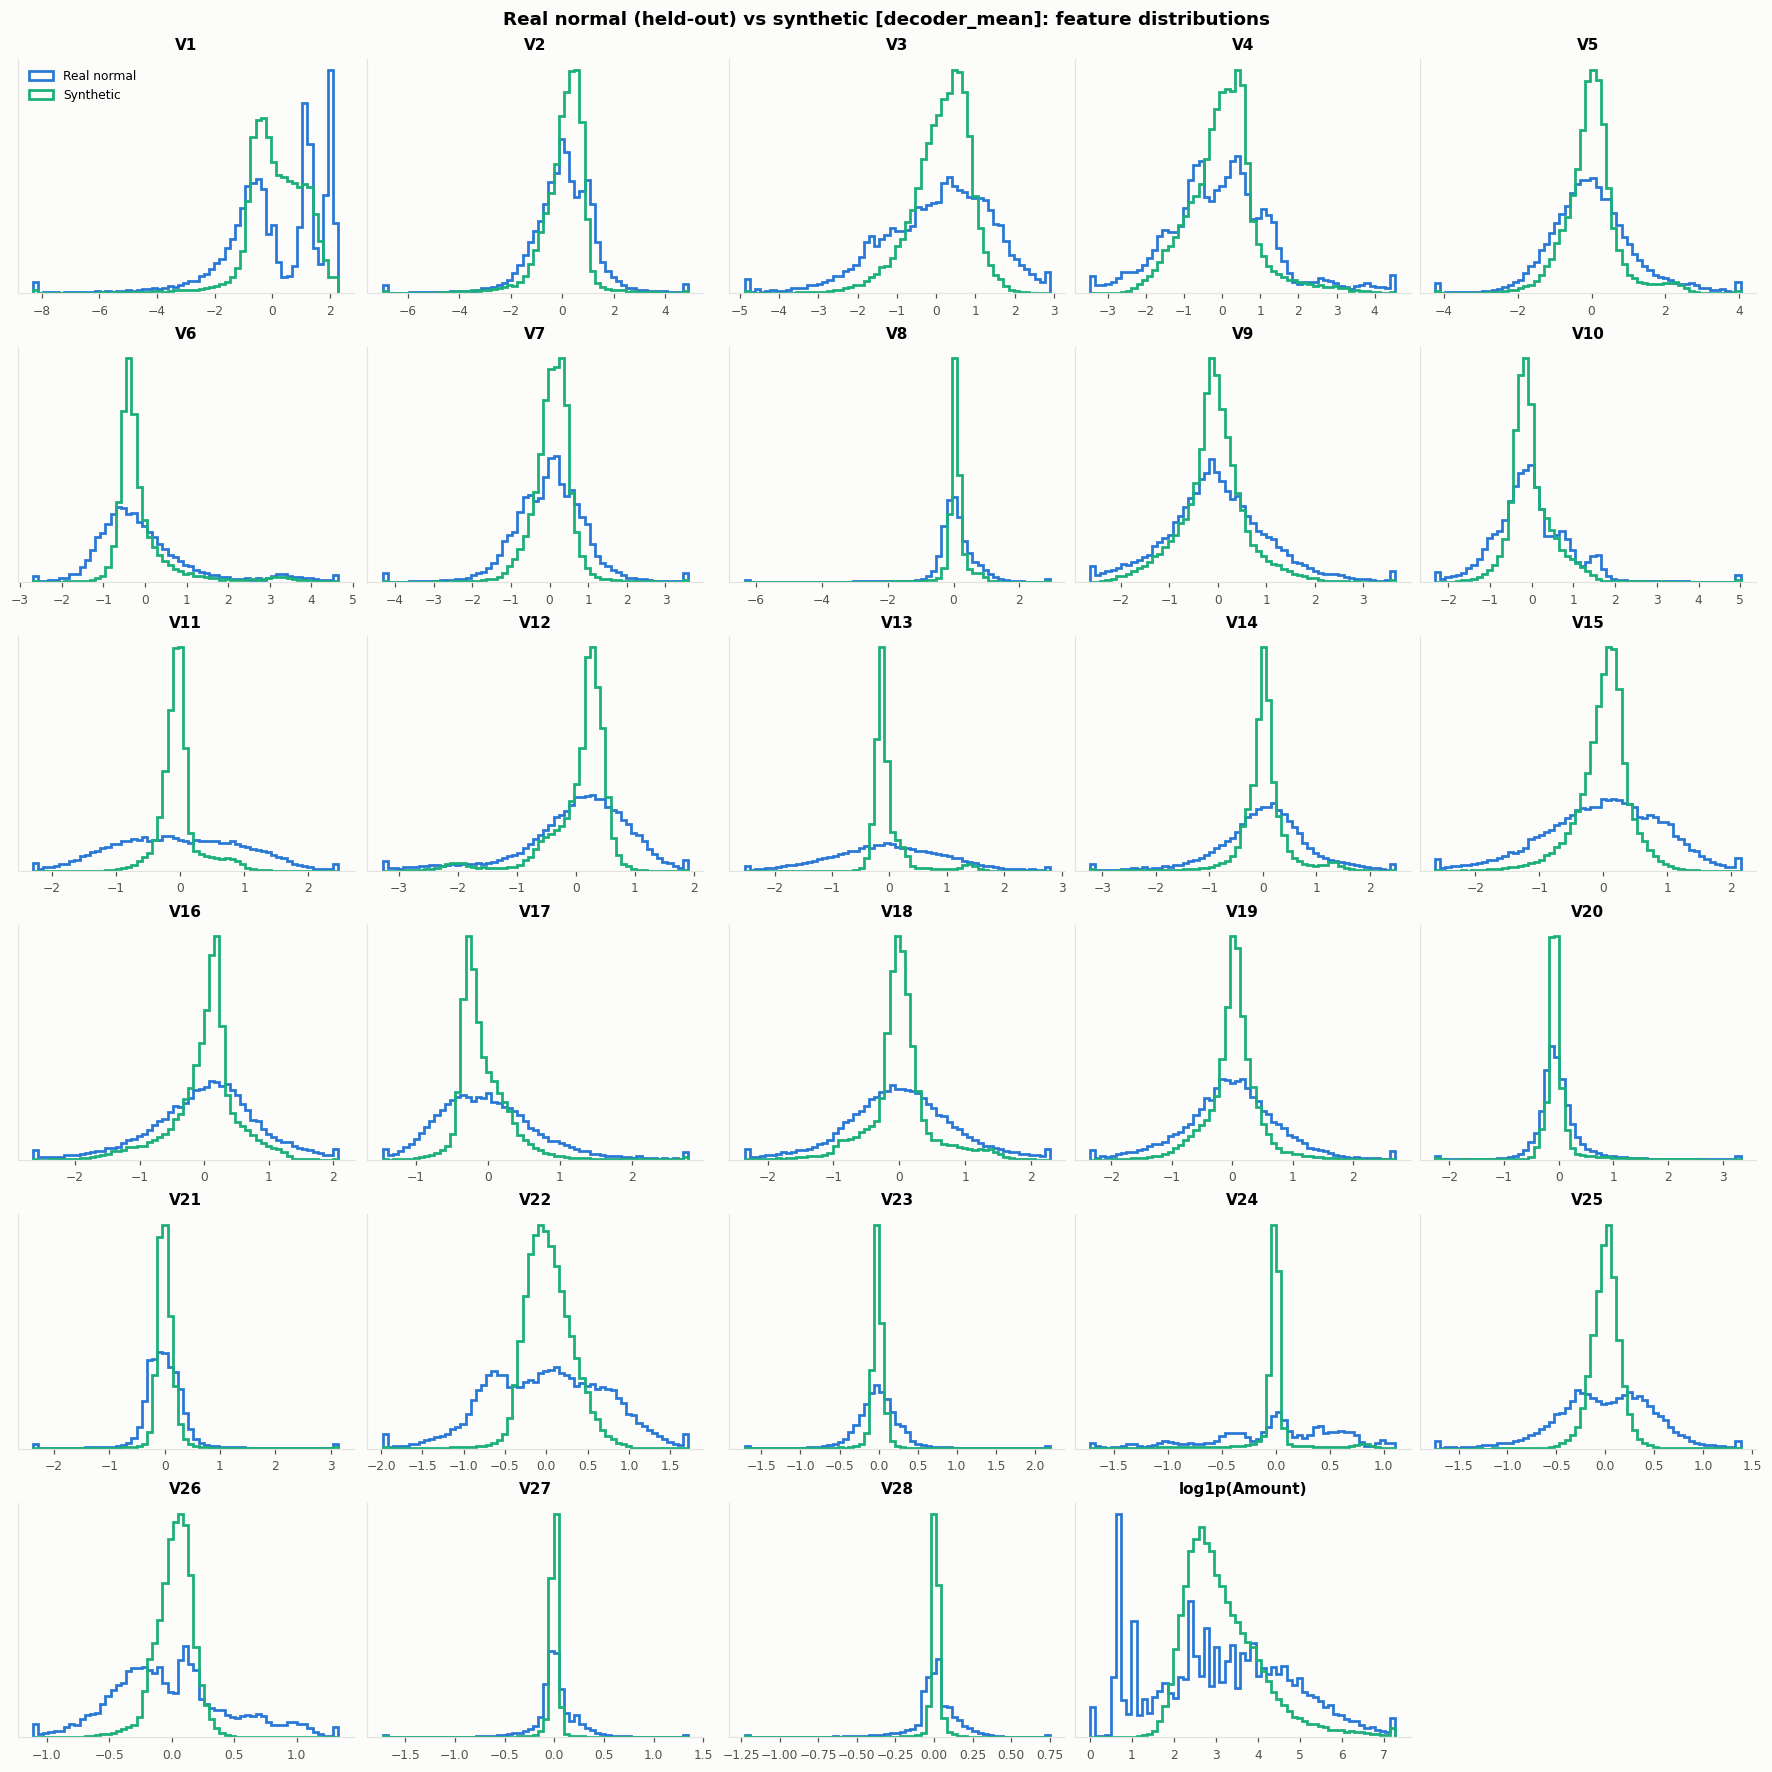

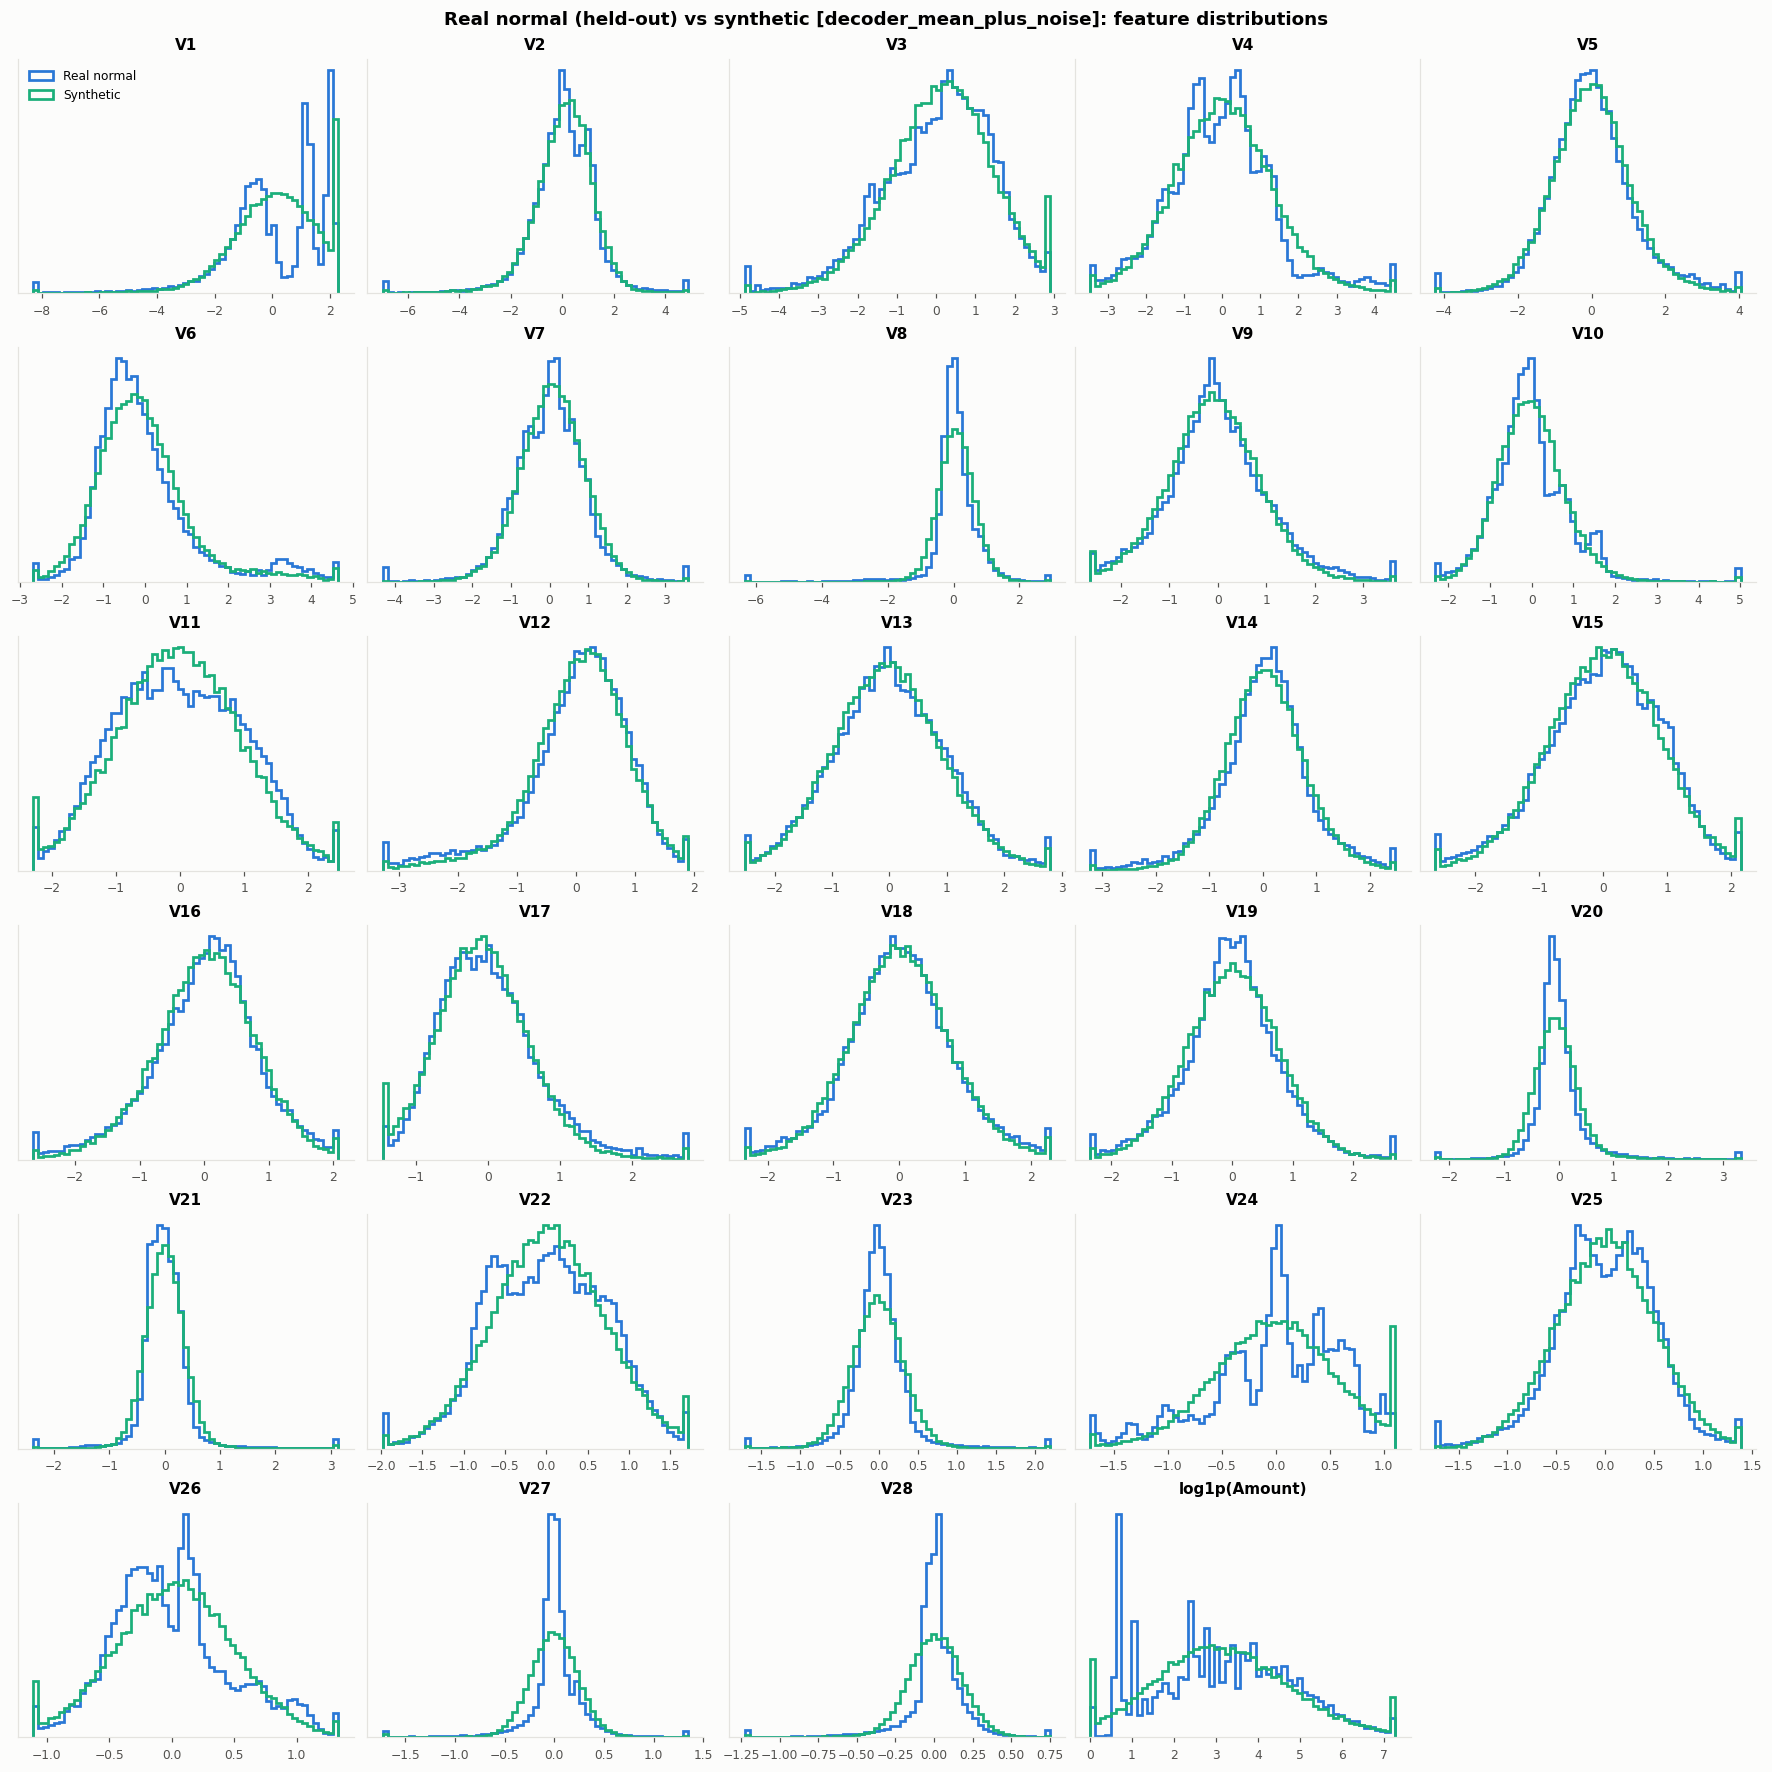

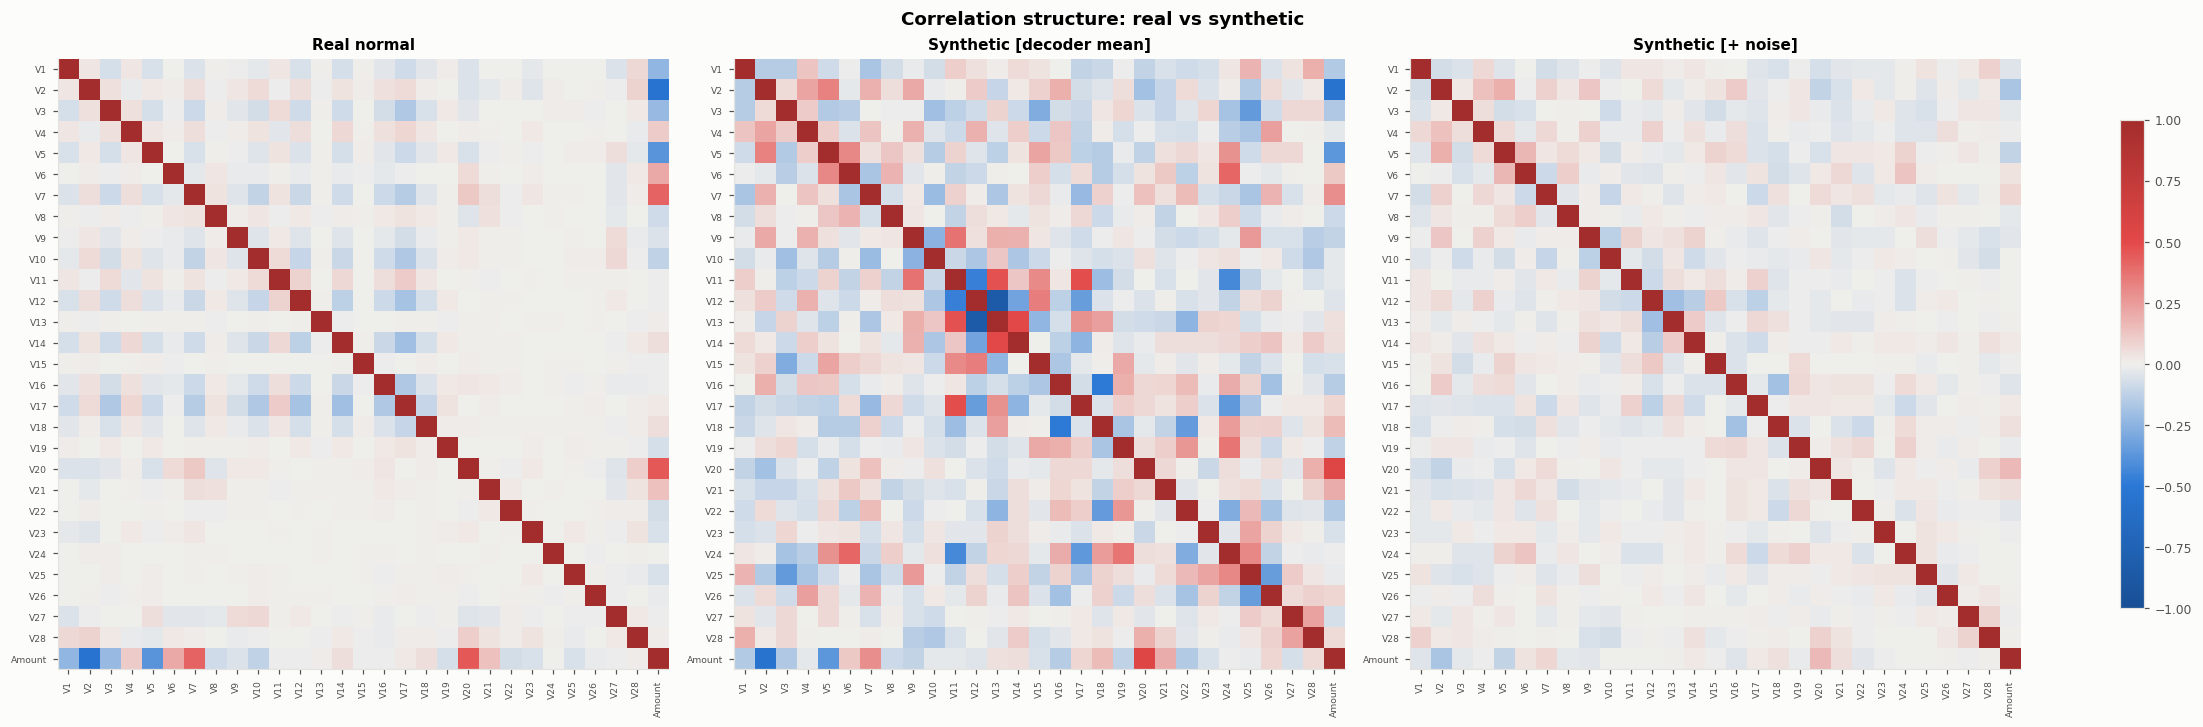

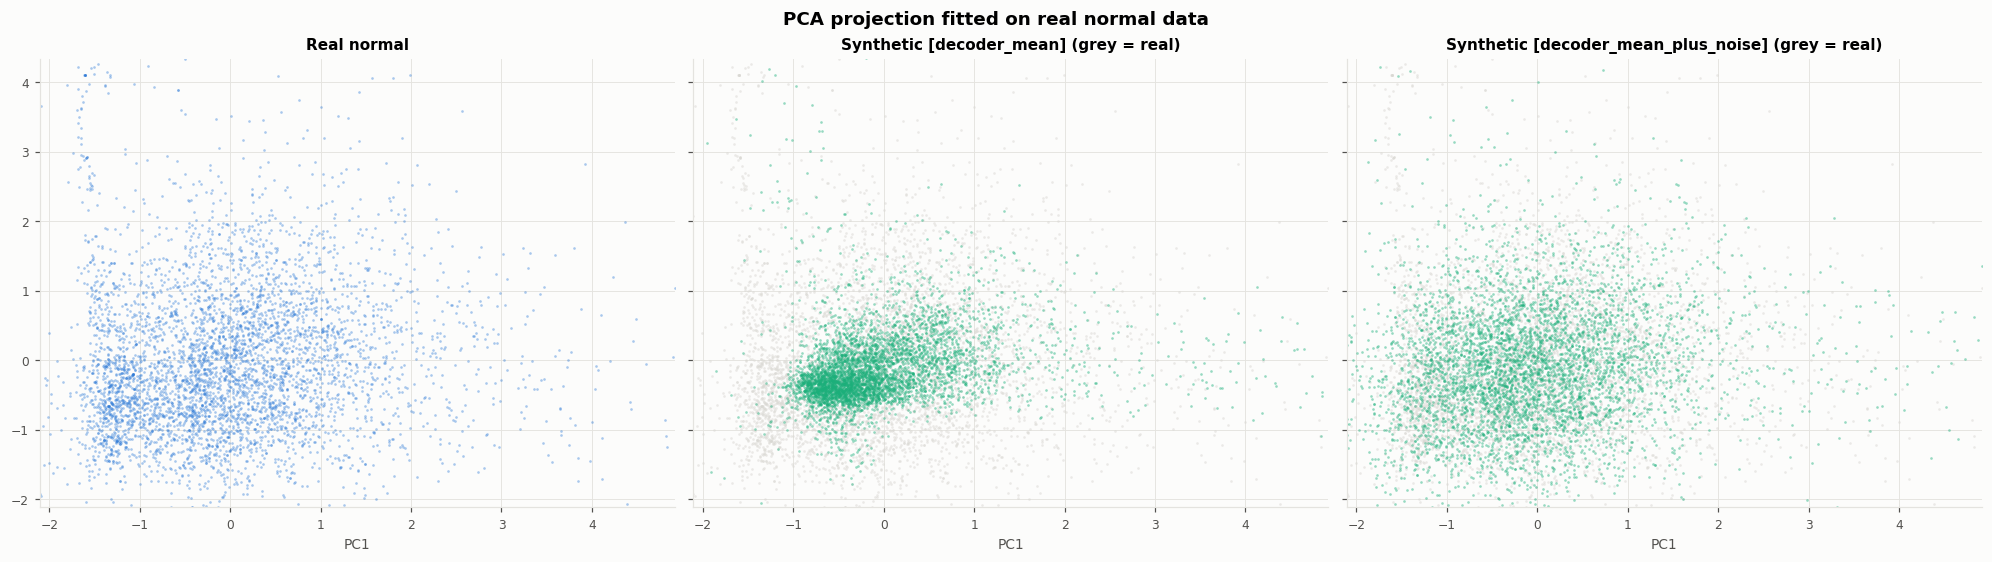

In [20]:
def plot_real_vs_synth(real, synth, name):
    fig, axes = plt.subplots(6, 5, figsize=(16, 16), layout="constrained")
    for ax, col in zip(axes.flat, RAW_INPUT_COLUMNS):
        r, s = (np.log1p(real[col]), np.log1p(synth[col])) if col == "Amount" else (real[col], synth[col])
        lo, hi = np.percentile(r, [0.5, 99.5])
        class_hist(ax, [np.clip(r, lo, hi), np.clip(s, lo, hi)], np.linspace(lo, hi, 60), labels=("Real normal", "Synthetic"), colors=(NORMAL_C, SYNTH_C))
        ax.set_title("log1p(Amount)" if col == "Amount" else col); ax.set_yticks([]); ax.grid(visible=False)
    axes.flat[-1].axis("off"); axes.flat[0].legend()
    fig.suptitle(f"Real normal (held-out) vs synthetic [{name}]: feature distributions")
    finish(fig, f"synthetic_distributions_{name}")

for name, v in SYNTHETIC.items():
    plot_real_vs_synth(real_ref, v["data"], name)

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), layout="constrained")
mats = [("Real normal", real_ref.corr()), ("Synthetic [decoder mean]", SYNTHETIC["decoder_mean"]["data"].corr()),
        ("Synthetic [+ noise]", SYNTHETIC["decoder_mean_plus_noise"]["data"].corr())]
for ax, (t, m) in zip(axes, mats):
    im = ax.imshow(m.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(29), RAW_INPUT_COLUMNS, rotation=90, fontsize=6); ax.set_yticks(range(29), RAW_INPUT_COLUMNS, fontsize=6)
    ax.grid(visible=False); ax.set_title(t)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.suptitle("Correlation structure: real vs synthetic")
finish(fig, "synthetic_correlations")

pca = PCA(2, random_state=0).fit(TF1.transform(real_ref, np.float64))
rp = pca.transform(TF1.transform(real_ref.sample(5000, random_state=0), np.float64))
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True, layout="constrained")
axes[0].scatter(rp[:, 0], rp[:, 1], s=3, color=NORMAL_C, alpha=0.4, linewidths=0); axes[0].set_title("Real normal")
for ax, name in zip(axes[1:], SYNTHETIC):
    sp = pca.transform(TF1.transform(SYNTHETIC[name]["data"].sample(5000, random_state=0), np.float64))
    ax.scatter(rp[:, 0], rp[:, 1], s=3, color="#d9d8d3", alpha=0.5, linewidths=0)
    ax.scatter(sp[:, 0], sp[:, 1], s=3, color=SYNTH_C, alpha=0.45, linewidths=0); ax.set_title(f"Synthetic [{name}] (grey = real)")
for ax in axes:
    ax.set_xlim(*np.percentile(rp[:, 0], [0.5, 99.5])); ax.set_ylim(*np.percentile(rp[:, 1], [0.5, 99.5])); ax.set_xlabel("PC1")
fig.suptitle("PCA projection fitted on real normal data")
finish(fig, "synthetic_pca")

## 16. Test-set anomaly detection

**Order of operations**, enforced by `TestLabelVault`:
1. Compute the reconstruction error of every test transaction.
2. Apply the saved validation threshold.
3. Save the predictions with a SHA-256 fingerprint.
4. Only then reveal the test labels.

**Secondary scores** are computed too: the negative ELBO and an importance-weighted estimate of −log p(x). These are likelihood-style estimates under the model, and **none of them is a fraud probability**.

In [21]:
LOG_2PI = math.log(2 * math.pi)

@torch.no_grad()
def neg_elbo(model, X, n_samples, seed, batch_size=4096):
    g = torch.Generator().manual_seed(seed)
    out = []
    for s in range(0, len(X), batch_size):
        x = torch.from_numpy(np.ascontiguousarray(X[s:s + batch_size])).to(DEVICE)
        mu, logvar = model.encode(x)
        rec = sum(0.5 * (x - model.decode(model.reparameterize(mu, logvar, g))).pow(2).sum(1) for _ in range(n_samples)) / n_samples
        out.append((rec + kl_divergence(mu, logvar) + 0.5 * x.shape[1] * LOG_2PI).double().cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def iwae_nll(model, X, n_samples, seed, batch_size=1024):
    g = torch.Generator().manual_seed(seed)
    d, D = model.cfg.latent_dim, model.cfg.input_dim
    out = []
    for s in range(0, len(X), batch_size):
        x = torch.from_numpy(np.ascontiguousarray(X[s:s + batch_size])).to(DEVICE)
        mu, logvar = model.encode(x)
        eps = torch.randn((n_samples, *mu.shape), generator=g).to(DEVICE)
        z = mu[None] + torch.exp(0.5 * logvar)[None] * eps
        recon = model.decode(z.reshape(-1, d)).reshape(n_samples, len(x), D)
        log_w = (-0.5 * (x[None] - recon).pow(2).sum(-1) - 0.5 * D * LOG_2PI) + (-0.5 * z.pow(2).sum(-1) - 0.5 * d * LOG_2PI) \
                - (-0.5 * (eps.pow(2) + logvar[None]).sum(-1) - 0.5 * d * LOG_2PI)
        out.append((-(torch.logsumexp(log_w, 0) - math.log(n_samples))).double().cpu())
    return torch.cat(out).numpy()

def score_and_save_predictions(exp: str) -> dict:
    """Steps 1-3 for every seed: no label is touched here."""
    sc = CONFIG["scores"]
    for seed, r in RUNS[exp].items():
        m = r["model"]
        assert np.allclose(recon_mse(m, DATA[exp]["X_val"]), r["val_scores"]), "validation scores changed since calibration"
        r["test_scores"] = {"recon_mse": recon_mse(m, DATA[exp]["X_test"]), "neg_elbo": neg_elbo(m, DATA[exp]["X_test"], sc["elbo_samples"], sc["seed"]),
                            "iwae_nll": iwae_nll(m, DATA[exp]["X_test"], sc["iwae_samples"], sc["seed"])}
        r["val_scores_secondary"] = {"neg_elbo": neg_elbo(m, DATA[exp]["X_val"], sc["elbo_samples"], sc["seed"]),
                                     "iwae_nll": iwae_nll(m, DATA[exp]["X_val"], sc["iwae_samples"], sc["seed"])}
        r["predicted"] = (r["test_scores"]["recon_mse"] > r["threshold"]).astype(int)
        path = DIRS["predictions"] / f"test_predictions_{exp}_seed{seed}.csv"
        pd.DataFrame({"dataset_row": PARTS["test"], "recon_mse": r["test_scores"]["recon_mse"], "predicted_anomaly": r["predicted"]}).to_csv(path, index=False)
        r["predictions_path"] = path
    bundle = DIRS["predictions"] / f"predictions_{exp}_all_seeds.csv"
    pd.concat([pd.read_csv(r["predictions_path"]).assign(seed=s) for s, r in RUNS[exp].items()]).to_csv(bundle, index=False)
    VAULT.register_predictions(exp, bundle)
    return RUNS[exp]

score_and_save_predictions("e1")
Y_TEST = VAULT.reveal("e1")      # step 4: labels are released only now
print(f"Test labels revealed after predictions were saved: {len(Y_TEST):,} rows, {int(Y_TEST.sum())} frauds")

Test labels revealed after predictions were saved: 42,720 rows, 73 frauds


## 17. Performance metrics and visualisations
Precision, recall and PR-AUC matter most with 0.17% fraud. A random scorer has AP ≈ prevalence (0.0017). The 5-seed mean ± std is the representative result; seed 0 was fixed in advance for the figures.

In [22]:
def threshold_metrics(y, s, tau):
    pred = s > tau
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    rc = tp / (tp + fn) if tp + fn else 0.0
    return {"threshold": float(tau), "tp": tp, "fp": fp, "fn": fn, "tn": tn, "precision": p, "recall": rc, "tpr": rc,
            "f1": 2 * p * rc / (p + rc) if p + rc else 0.0, "fpr": fp / (fp + tn), "flagged": tp + fp}

def bootstrap_ci(y, s, tau, n, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    draws = {k: [] for k in ("average_precision", "roc_auc", "precision", "recall", "f1", "fpr")}
    for _ in range(n):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        draws["average_precision"].append(average_precision_score(y[idx], s[idx])); draws["roc_auc"].append(roc_auc_score(y[idx], s[idx]))
        m = threshold_metrics(y[idx], s[idx], tau)
        for k in ("precision", "recall", "f1", "fpr"):
            draws[k].append(m[k])
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in draws.items()}

def evaluate_experiment(exp: str, y: np.ndarray) -> pd.DataFrame:
    rows = []
    for seed, r in RUNS[exp].items():
        s = r["test_scores"]["recon_mse"]
        m = {**threshold_metrics(y, s, r["threshold"]), "average_precision": average_precision_score(y, s), "roc_auc": roc_auc_score(y, s)}
        for name in ("neg_elbo", "iwae_nll"):
            m[f"ap_{name}"] = average_precision_score(y, r["test_scores"][name])
        r["metrics"] = m
        rows.append({"experiment": exp, "seed": seed, **m, "best_epoch": r["best_epoch"], "runtime_s": r["runtime_s"]})
    return pd.DataFrame(rows)

PER_SEED = evaluate_experiment("e1", Y_TEST)
METRIC_COLS = ["average_precision", "roc_auc", "precision", "recall", "f1", "fpr", "tpr"]
display(PER_SEED[["seed", *METRIC_COLS, "tp", "fp", "fn", "tn", "threshold"]].round(4))
hm = RUNS["e1"][hs]["metrics"]
CI = bootstrap_ci(Y_TEST, RUNS["e1"][hs]["test_scores"]["recon_mse"], hm["threshold"], CONFIG["evaluation"]["bootstrap_resamples"], CONFIG["evaluation"]["bootstrap_seed"])
HEADLINE = pd.DataFrame({"value": {k: hm[k] for k in CI}, "ci_low": {k: CI[k][0] for k in CI}, "ci_high": {k: CI[k][1] for k in CI}})
HEADLINE.to_csv(DIRS["metrics"] / "headline_metrics_e1_seed0.csv")
order = np.argsort(-RUNS["e1"][hs]["test_scores"]["recon_mse"], kind="stable")
BUDGETS = {k: int(Y_TEST[order[:k]].sum()) for k in CONFIG["evaluation"]["alert_budgets"]}
print("E1 mean ± std over seeds:", {k: f"{PER_SEED[k].mean():.4f} ± {PER_SEED[k].std():.4f}" for k in METRIC_COLS})
print(f"Headline seed {hs}: TP {hm['tp']}, FP {hm['fp']}, FN {hm['fn']}, TN {hm['tn']}; frauds in top-k alerts: {BUDGETS}")
HEADLINE.round(4)

,seed,average_precision,roc_auc,precision,recall,f1,fpr,tpr,tp,fp,fn,tn,threshold
0,0,0.4922,0.9604,0.1175,0.7534,0.2033,0.0097,0.7534,55,413,18,42234,1.2292
1,1,0.4128,0.9540,0.0918,0.6301,0.1603,0.0107,0.6301,46,455,27,42192,1.2303
2,2,0.4608,0.9429,0.1171,0.6849,0.2000,0.0088,0.6849,50,377,23,42270,1.2839
3,3,0.3692,0.9213,0.0956,0.5616,0.1633,0.0091,0.5616,41,388,32,42259,1.2342
4,4,0.4229,0.9547,0.0962,0.6301,0.1670,0.0101,0.6301,46,432,27,42215,1.2178


E1 mean ± std over seeds: {'average_precision': '0.4316 ± 0.0470', 'roc_auc': '0.9467 ± 0.0155', 'precision': '0.1036 ± 0.0126', 'recall': '0.6521 ± 0.0716', 'f1': '0.1788 ± 0.0211', 'fpr': '0.0097 ± 0.0007', 'tpr': '0.6521 ± 0.0716'}
Headline seed 0: TP 55, FP 413, FN 18, TN 42234; frauds in top-k alerts: {100: 40, 500: 56, 1000: 60}


,value,ci_low,ci_high
average_precision,0.4922,0.3760,0.6181
roc_auc,0.9604,0.9260,0.9881
precision,0.1175,0.1004,0.1344
recall,0.7534,0.6438,0.8493
f1,0.2033,0.1741,0.2305
fpr,0.0097,0.0088,0.0106


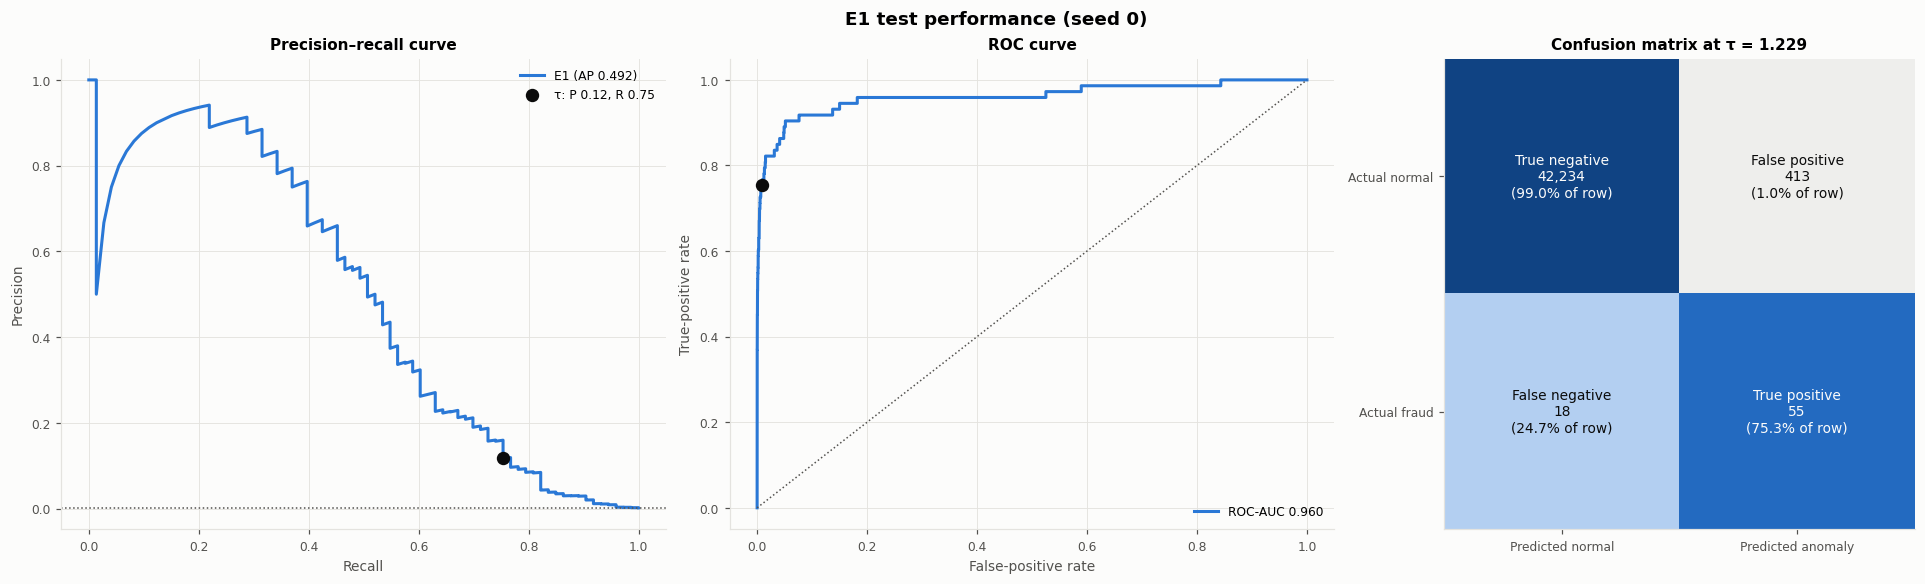

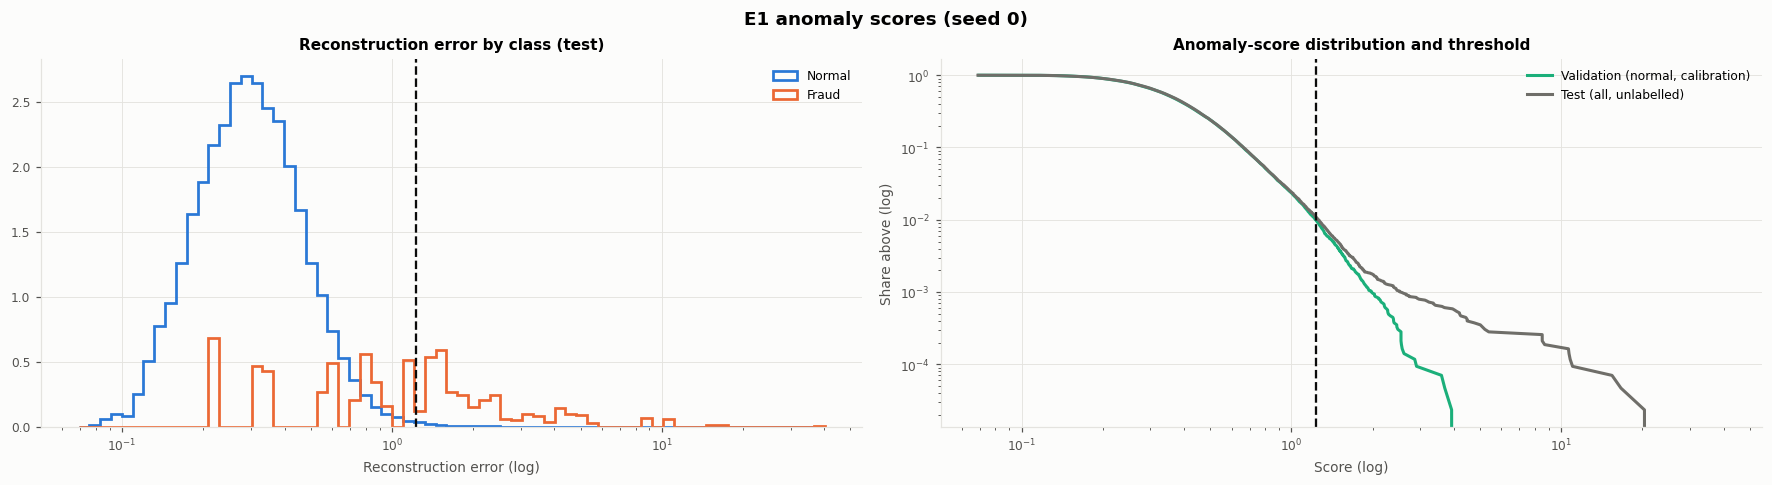

In [23]:
s1 = RUNS["e1"][hs]["test_scores"]["recon_mse"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), layout="constrained")
p, rc, thr = precision_recall_curve(Y_TEST, s1)
axes[0].plot(rc, p, color=NORMAL_C, linewidth=2, label=f"E1 (AP {hm['average_precision']:.3f})")
axes[0].scatter([hm["recall"]], [hm["precision"]], color=TEXT, s=60, zorder=3, label=f"τ: P {hm['precision']:.2f}, R {hm['recall']:.2f}")
axes[0].axhline(Y_TEST.mean(), color=TEXT2, linestyle=":", linewidth=1); axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision–recall curve"); axes[0].legend()
fpr_c, tpr_c, _ = roc_curve(Y_TEST, s1)
axes[1].plot(fpr_c, tpr_c, color=NORMAL_C, linewidth=2, label=f"ROC-AUC {hm['roc_auc']:.3f}")
axes[1].scatter([hm["fpr"]], [hm["tpr"]], color=TEXT, s=60, zorder=3); axes[1].plot([0, 1], [0, 1], color=TEXT2, linestyle=":", linewidth=1)
axes[1].set_xlabel("False-positive rate"); axes[1].set_ylabel("True-positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
cm = np.array([[hm["tn"], hm["fp"]], [hm["fn"], hm["tp"]]]); share = cm / cm.sum(1, keepdims=True)
axes[2].imshow(share, cmap=SEQ_BLUE, vmin=0, vmax=1)
labels = [["True negative", "False positive"], ["False negative", "True positive"]]
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}\n({100 * share[i, j]:.1f}% of row)", ha="center", va="center", fontsize=9,
                     color=SURFACE if share[i, j] > 0.5 else TEXT)
axes[2].set_xticks([0, 1], ["Predicted normal", "Predicted anomaly"]); axes[2].set_yticks([0, 1], ["Actual normal", "Actual fraud"])
axes[2].grid(visible=False); axes[2].set_title(f"Confusion matrix at τ = {hm['threshold']:.3f}")
fig.suptitle(f"E1 test performance (seed {hs})")
finish(fig, "test_pr_roc_confusion_e1")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), layout="constrained")
bins = np.logspace(np.log10(s1.min()), np.log10(s1.max()), 70)
class_hist(axes[0], [s1[Y_TEST == 0], s1[Y_TEST == 1]], bins, log_x=True)
axes[0].axvline(hm["threshold"], color=TEXT, linestyle="--"); axes[0].set_title("Reconstruction error by class (test)"); axes[0].legend()
axes[0].set_xlabel("Reconstruction error (log)")
for scores_, color, lab in ((RUNS["e1"][hs]["val_scores"], SYNTH_C, "Validation (normal, calibration)"), (s1, E2_C, "Test (all, unlabelled)")):
    v = np.sort(scores_); axes[1].plot(v, 1 - np.arange(1, len(v) + 1) / len(v), color=color, linewidth=2, label=lab)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].axvline(hm["threshold"], color=TEXT, linestyle="--")
axes[1].set_title("Anomaly-score distribution and threshold"); axes[1].set_xlabel("Score (log)"); axes[1].set_ylabel("Share above (log)"); axes[1].legend()
fig.suptitle(f"E1 anomaly scores (seed {hs})")
finish(fig, "test_score_distributions_e1")

**Threshold sensitivity** (post-hoc). Each alternative threshold is a *validation* percentile applied to the test set. The primary τ (p99) was fixed before testing and is **not** changed after looking at these results.

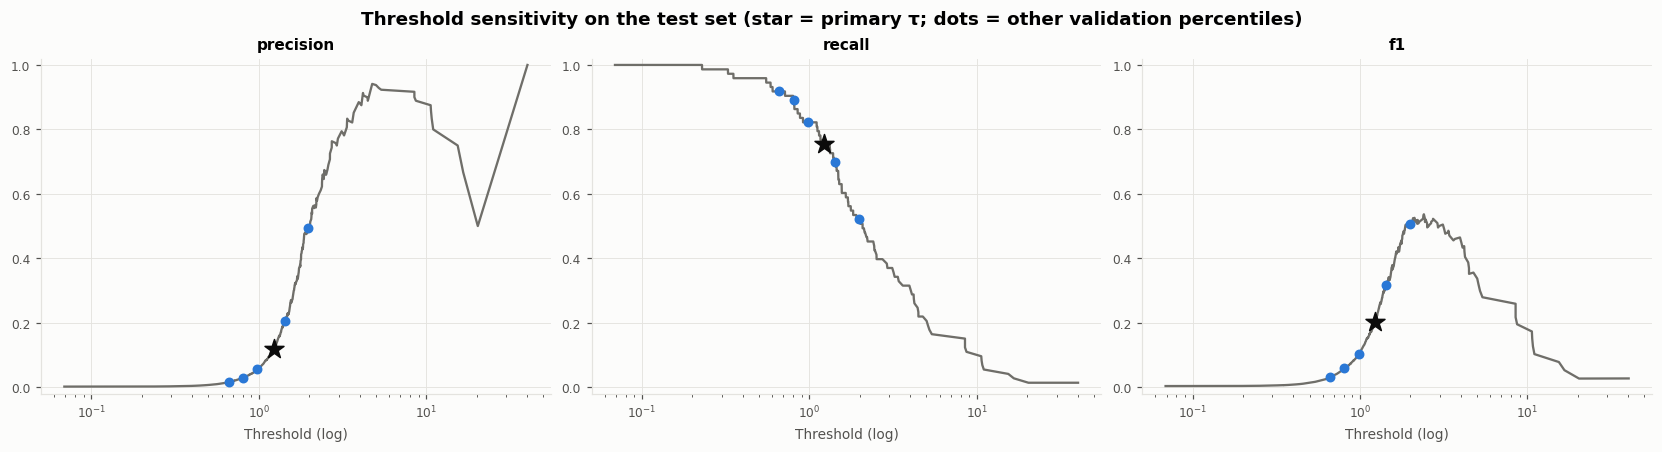

,validation_percentile,role,threshold,flagged,tp,fp,fn,precision,recall,f1,fpr
0,90.0,sensitivity,0.6627,4314,67,4247,6,0.0155,0.9178,0.0305,0.0996
1,95.0,sensitivity,0.8069,2171,65,2106,8,0.0299,0.8904,0.0579,0.0494
2,97.5,sensitivity,0.9815,1094,60,1034,13,0.0548,0.8219,0.1028,0.0242
3,99.0,primary,1.2292,468,55,413,18,0.1175,0.7534,0.2033,0.0097
4,99.5,sensitivity,1.4260,249,51,198,22,0.2048,0.6986,0.3168,0.0046
5,99.9,sensitivity,1.9801,77,38,39,35,0.4935,0.5205,0.5067,0.0009


In [24]:
val1 = RUNS["e1"][hs]["val_scores"]
SENSITIVITY = pd.DataFrame([{"validation_percentile": q, "role": "primary" if q == CONFIG["threshold_percentile"] else "sensitivity",
                             **threshold_metrics(Y_TEST, s1, float(np.percentile(val1, q)))} for q in CONFIG["sensitivity_percentiles"]])
SENSITIVITY.to_csv(DIRS["metrics"] / "threshold_sensitivity_e1_seed0.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, layout="constrained")
pr, rcl, th = precision_recall_curve(Y_TEST, s1)
f1c = np.where(pr + rcl > 0, 2 * pr * rcl / np.maximum(pr + rcl, 1e-12), 0)
for ax, vals, key in ((axes[0], pr, "precision"), (axes[1], rcl, "recall"), (axes[2], f1c, "f1")):
    ax.plot(th, vals[:-1], color=E2_C, linewidth=1.5)
    sens = SENSITIVITY[SENSITIVITY.role == "sensitivity"]; prim = SENSITIVITY[SENSITIVITY.role == "primary"]
    ax.scatter(sens.threshold, sens[key], color=NORMAL_C, s=30, zorder=3); ax.scatter(prim.threshold, prim[key], color=TEXT, marker="*", s=170, zorder=4)
    ax.set_xscale("log"); ax.set_title(key); ax.set_ylim(-0.02, 1.02); ax.set_xlabel("Threshold (log)")
fig.suptitle("Threshold sensitivity on the test set (star = primary τ; dots = other validation percentiles)")
finish(fig, "threshold_sensitivity_e1")
SENSITIVITY[["validation_percentile", "role", "threshold", "flagged", "tp", "fp", "fn", "precision", "recall", "f1", "fpr"]].round(4)

## 18. Secondary experiment: E2, a fully unsupervised VAE

Same architecture, hyperparameters, seeds and evaluation, but trained on **all** training transactions (normal *and* fraud) with labels ignored everywhere: training, early stopping and threshold (99th percentile of *all* validation scores). It is evaluated on the **same** test set.

In [25]:
RUNS["e2"] = train_experiment("e2")
score_and_save_predictions("e2")
Y_TEST_E2 = VAULT.reveal("e2")
assert np.array_equal(Y_TEST, Y_TEST_E2)
PER_SEED = pd.concat([PER_SEED, evaluate_experiment("e2", Y_TEST_E2)], ignore_index=True)
PER_SEED.to_csv(DIRS["metrics"] / "detection_metrics_per_seed.csv", index=False)
SUMMARY = PER_SEED.groupby("experiment")[METRIC_COLS + ["ap_neg_elbo", "ap_iwae_nll"]].agg(["mean", "std"])
SUMMARY.to_csv(DIRS["metrics"] / "detection_metrics_summary.csv")
display(training_table("e2").round(4))
SUMMARY.round(4)

[e2 seed 0] training on 199,366 rows on cpu
    epoch  50  train 10.3420  val 10.3419
    epoch 100  train 10.1936  val 10.2077
    epoch 150  train 10.1087  val 10.1364
    epoch 200  train 10.0720  val 10.1163
[e2 seed 0] best epoch 191/201, 78s, threshold 1.2613
[e2 seed 1] training on 199,366 rows on cpu
    epoch  50  train 10.3291  val 10.3422
    epoch 100  train 10.1892  val 10.1992
    epoch 150  train 10.1306  val 10.1614
    epoch 200  train 10.0805  val 10.1045
[e2 seed 1] best epoch 190/200, 79s, threshold 1.3297
[e2 seed 2] training on 199,366 rows on cpu
    epoch  50  train 10.3688  val 10.3725
    epoch 100  train 10.2446  val 10.2567
[e2 seed 2] best epoch 131/141, 55s, threshold 1.2626
[e2 seed 3] training on 199,366 rows on cpu
    epoch  50  train 10.2577  val 10.2628
    epoch 100  train 10.1228  val 10.1320
    epoch 150  train 10.0784  val 10.0980
[e2 seed 3] best epoch 163/173, 68s, threshold 1.2143
[e2 seed 4] training on 199,366 rows on cpu
    epoch  50  tra

,best_epoch,epochs_run,runtime_s,best_val_neg_elbo,val_recon_mse,threshold
seed,,,,,,
0,191,201,78.4,10.0976,0.4088,1.2613
1,190,200,78.7,10.0941,0.4237,1.3297
2,131,141,55.1,10.1799,0.4124,1.2626
3,163,173,67.9,10.0661,0.4286,1.2143
4,96,106,41.9,10.2283,0.4244,1.2748


average_precision         roc_auc         precision          recall              f1             fpr             tpr         ap_neg_elbo         ap_iwae_nll        
                        mean     std    mean     std      mean     std    mean     std    mean     std    mean     std    mean     std        mean     std        mean     std
experiment                                                                                                                                                                    
e1                    0.4316  0.0470  0.9467  0.0155    0.1036  0.0126  0.6521  0.0716  0.1788  0.0211  0.0097  0.0007  0.6521  0.0716      0.4499  0.0397      0.4200  0.0377
e2                    0.0377  0.0161  0.8633  0.0162    0.0423  0.0035  0.2630  0.0245  0.0729  0.0059  0.0102  0.0006  0.2630  0.0245      0.1168  0.0148      0.1193  0.0146

## 19. Comparative analysis: E1 vs E2

In [26]:
LABEL = {"e1": "E1 normal-only", "e2": "E2 unsupervised"}
comp_rows = []
for key, name in [("average_precision", "PR-AUC"), ("roc_auc", "ROC-AUC"), ("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"),
                  ("fpr", "False-positive rate"), ("best_epoch", "Best epoch"), ("runtime_s", "Training time (s)")]:
    a, b = PER_SEED.loc[PER_SEED.experiment == "e1", key].to_numpy(), PER_SEED.loc[PER_SEED.experiment == "e2", key].to_numpy()
    comp_rows.append({"metric": name, "E1 mean": a.mean(), "E1 std": a.std(ddof=1), "E2 mean": b.mean(), "E2 std": b.std(ddof=1),
                      "E1 − E2": a.mean() - b.mean(), "seeds E1 higher": int((a > b).sum())})
COMPARISON = pd.DataFrame(comp_rows).set_index("metric")
COMPARISON.to_csv(DIRS["metrics"] / "comparison_e1_vs_e2.csv")
s2 = RUNS["e2"][hs]["test_scores"]["recon_mse"]
rng = np.random.default_rng(CONFIG["evaluation"]["bootstrap_seed"])
pos, neg = np.flatnonzero(Y_TEST == 1), np.flatnonzero(Y_TEST == 0)
diffs = []
for _ in range(CONFIG["evaluation"]["bootstrap_resamples"]):
    idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    diffs.append(average_precision_score(Y_TEST[idx], s1[idx]) - average_precision_score(Y_TEST[idx], s2[idx]))
PAIRED = {"observed": average_precision_score(Y_TEST, s1) - average_precision_score(Y_TEST, s2),
          "ci_low": float(np.percentile(diffs, 2.5)), "ci_high": float(np.percentile(diffs, 97.5))}
SEPARATION = {e: float(np.median(RUNS[e][hs]["test_scores"]["recon_mse"][Y_TEST == 1]) / np.median(RUNS[e][hs]["test_scores"]["recon_mse"][Y_TEST == 0])) for e in RUNS}
FRAUD_MEDIAN = {e: float(np.median(RUNS[e][hs]["test_scores"]["recon_mse"][Y_TEST == 1])) for e in RUNS}
Xtr2 = DATA["e2"]["X_train"].astype(np.float64); y_tr2 = y_all[PARTS["e2_train"]]
FRAUD_SQ_SHARE = float((Xtr2[y_tr2 == 1] ** 2).sum() / (Xtr2 ** 2).sum())
print("Paired bootstrap AP(E1) − AP(E2), seed 0:", {k: round(v, 3) for k, v in PAIRED.items()})
print("Median fraud/normal error ratio:", {k: round(v, 2) for k, v in SEPARATION.items()}, "| median test-fraud error:", {k: round(v, 3) for k, v in FRAUD_MEDIAN.items()})
print(f"Training frauds are {100 * y_tr2.mean():.2f}% of E2's training rows but {100 * FRAUD_SQ_SHARE:.1f}% of its total squared feature magnitude")
COMPARISON.round(4)

Paired bootstrap AP(E1) − AP(E2), seed 0: {'observed': 0.462, 'ci_low': 0.351, 'ci_high': 0.575}
Median fraud/normal error ratio: {'e1': 5.74, 'e2': 2.46} | median test-fraud error: {'e1': 2.078, 'e2': 0.862}
Training frauds are 0.17% of E2's training rows but 4.1% of its total squared feature magnitude


,E1 mean,E1 std,E2 mean,E2 std,E1 − E2,seeds E1 higher
metric,,,,,,
PR-AUC,0.4316,0.0470,0.0377,0.0161,0.3938,5
ROC-AUC,0.9467,0.0155,0.8633,0.0162,0.0834,5
Precision,0.1036,0.0126,0.0423,0.0035,0.0613,5
Recall,0.6521,0.0716,0.2630,0.0245,0.3890,5
F1,0.1788,0.0211,0.0729,0.0059,0.1059,5
False-positive rate,0.0097,0.0007,0.0102,0.0006,-0.0005,1
Best epoch,167.8000,52.6517,154.2000,40.7394,13.6000,3
Training time (s),69.1953,20.3704,64.3797,15.8506,4.8155,3


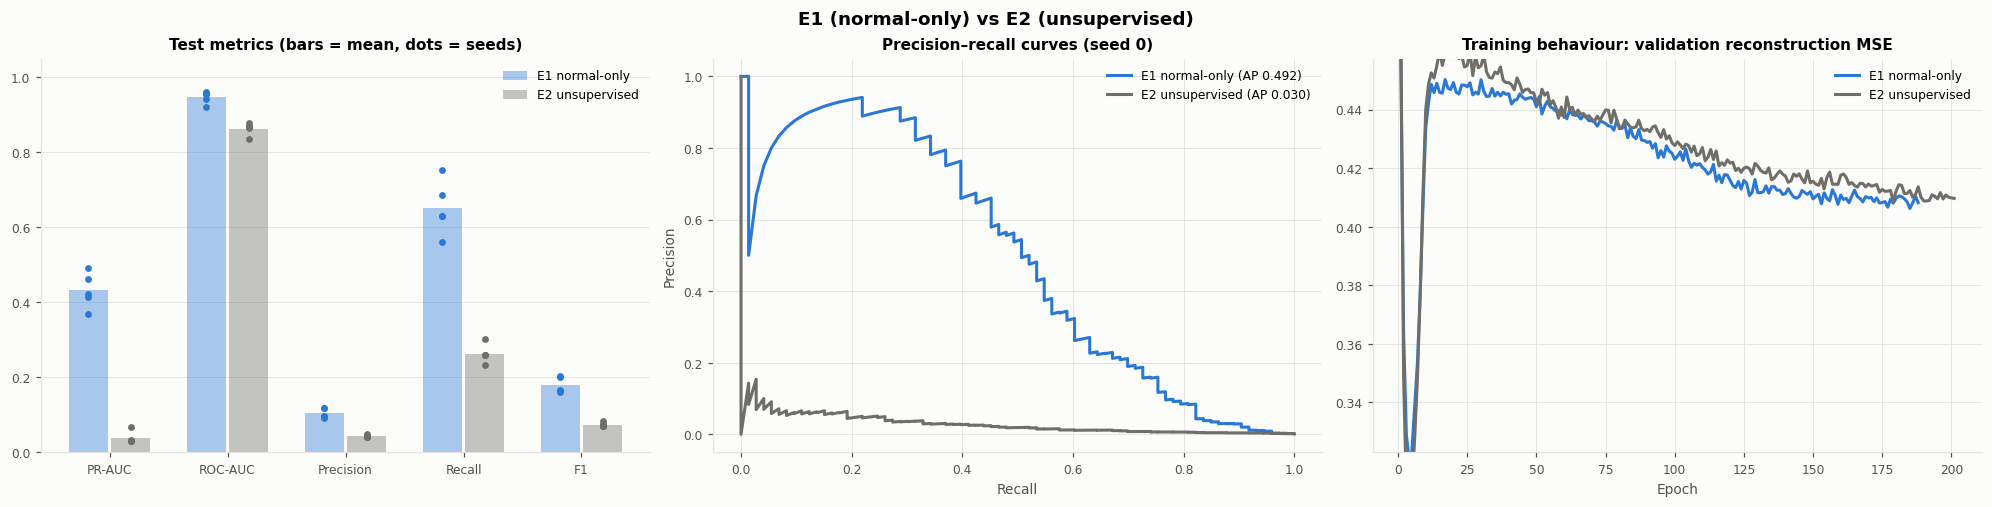

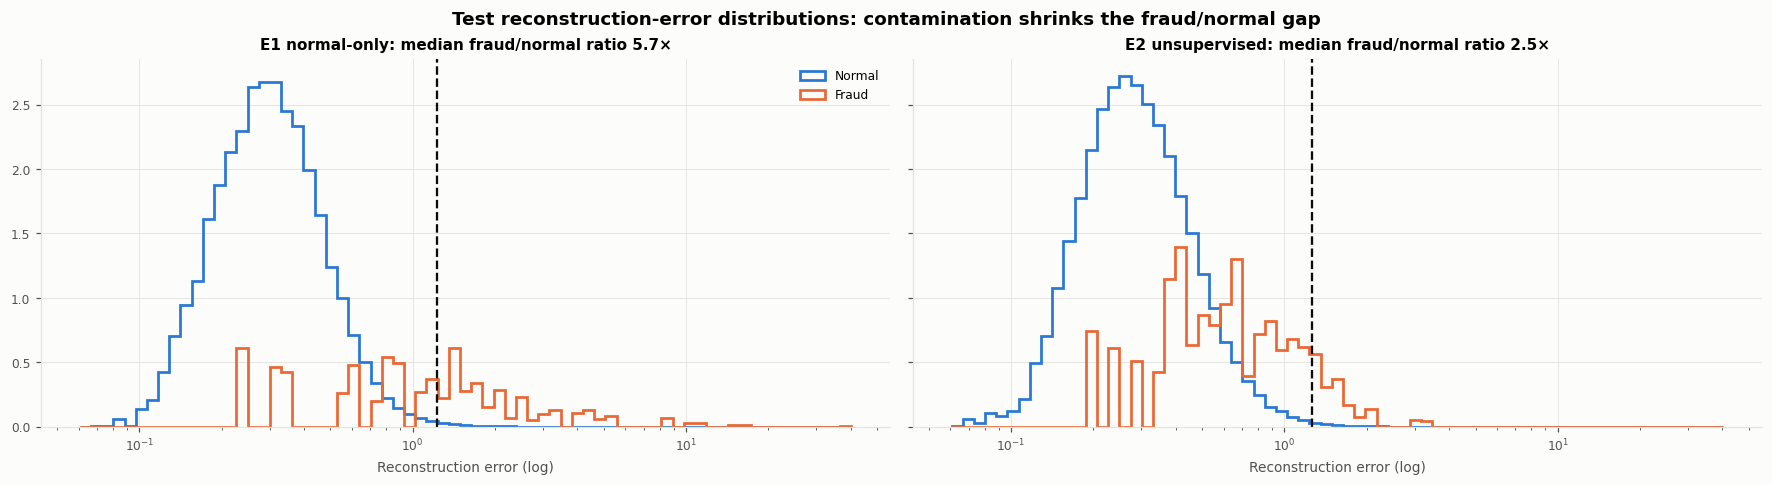

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), layout="constrained")
metrics_ = [("average_precision", "PR-AUC"), ("roc_auc", "ROC-AUC"), ("precision", "Precision"), ("recall", "Recall"), ("f1", "F1")]
for j, (exp, color) in enumerate((("e1", NORMAL_C), ("e2", E2_C))):
    sub = PER_SEED[PER_SEED.experiment == exp]
    x = np.arange(len(metrics_)) + (j - 0.5) * 0.36
    axes[0].bar(x, [sub[m].mean() for m, _ in metrics_], width=0.33, color=color, alpha=0.4, label=LABEL[exp])
    for i, (m, _) in enumerate(metrics_):
        axes[0].scatter(np.full(len(sub), x[i]), sub[m], color=color, s=12, zorder=3)
axes[0].set_xticks(range(len(metrics_)), [n for _, n in metrics_]); axes[0].set_ylim(0, 1.05); axes[0].legend(); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Test metrics (bars = mean, dots = seeds)")
for exp, color in (("e1", NORMAL_C), ("e2", E2_C)):
    pr_, rc_, _ = precision_recall_curve(Y_TEST, RUNS[exp][hs]["test_scores"]["recon_mse"])
    axes[1].plot(rc_, pr_, color=color, linewidth=2, label=f"{LABEL[exp]} (AP {RUNS[exp][hs]['metrics']['average_precision']:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend(); axes[1].set_title(f"Precision–recall curves (seed {hs})")
for exp, color in (("e1", NORMAL_C), ("e2", E2_C)):
    h = RUNS[exp][hs]["history"]
    axes[2].plot(h.epoch, h.val_recon_mse_det, color=color, linewidth=2, label=LABEL[exp])
axes[2].set_ylim(np.percentile(np.r_[RUNS["e1"][hs]["history"].val_recon_mse_det, RUNS["e2"][hs]["history"].val_recon_mse_det], [1, 97]))
axes[2].set_xlabel("Epoch"); axes[2].set_title("Training behaviour: validation reconstruction MSE"); axes[2].legend()
fig.suptitle("E1 (normal-only) vs E2 (unsupervised)")
finish(fig, "comparison_e1_vs_e2")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), sharex=True, sharey=True, layout="constrained")
bins = np.logspace(np.log10(min(s1.min(), s2.min())), np.log10(max(s1.max(), s2.max())), 70)
for ax, exp in zip(axes, ("e1", "e2")):
    s_ = RUNS[exp][hs]["test_scores"]["recon_mse"]
    class_hist(ax, [s_[Y_TEST == 0], s_[Y_TEST == 1]], bins, log_x=True)
    ax.axvline(RUNS[exp][hs]["threshold"], color=TEXT, linestyle="--")
    ax.set_title(f"{LABEL[exp]}: median fraud/normal ratio {SEPARATION[exp]:.1f}×"); ax.set_xlabel("Reconstruction error (log)")
axes[0].legend()
fig.suptitle("Test reconstruction-error distributions: contamination shrinks the fraud/normal gap")
finish(fig, "comparison_score_distributions")

## 20. Latent-space visualisation and reconstruction behaviour
Test transactions are encoded to their posterior means μ and projected to 2-D with PCA. They are coloured by class **only after training**; the models never saw a label.

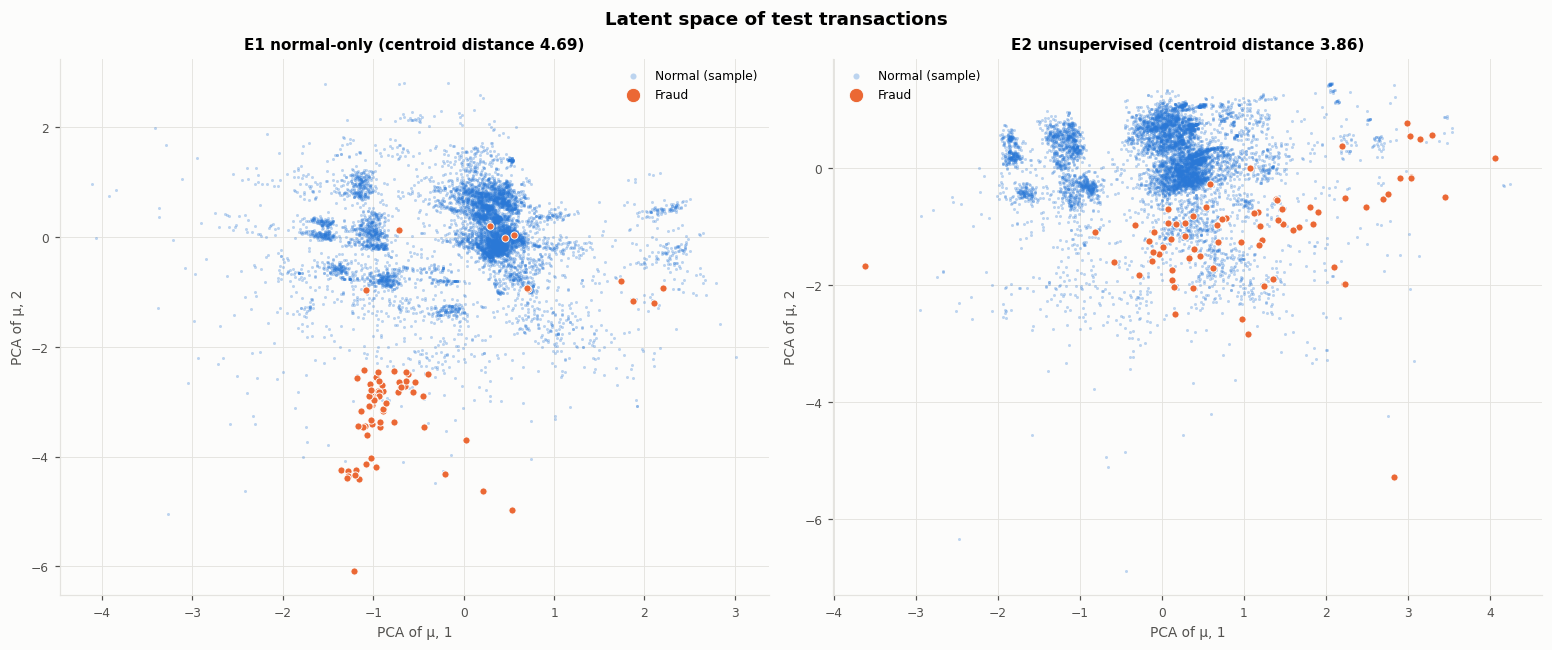

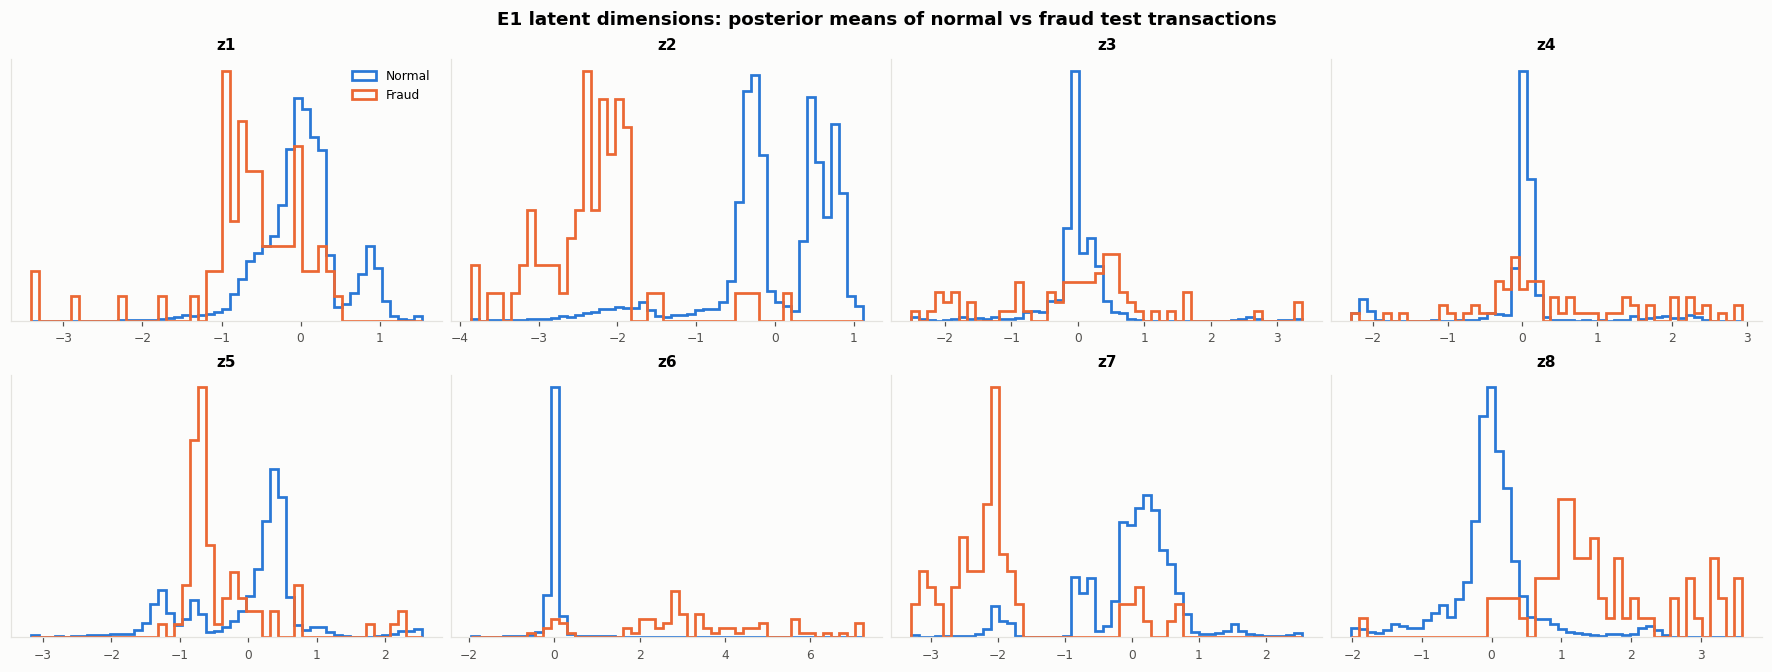

In [28]:
@torch.no_grad()
def encode_mu(model, X):
    return np.concatenate([model.encode(torch.from_numpy(np.ascontiguousarray(X[s:s + 8192])).to(DEVICE))[0].cpu().numpy() for s in range(0, len(X), 8192)])

MU = {e: encode_mu(RUNS[e][hs]["model"], DATA[e]["X_test"]) for e in RUNS}
LATENT = {e: {"median_norm_normal": float(np.median(np.linalg.norm(MU[e][Y_TEST == 0], axis=1))),
              "median_norm_fraud": float(np.median(np.linalg.norm(MU[e][Y_TEST == 1], axis=1))),
              "centroid_distance": float(np.linalg.norm(MU[e][Y_TEST == 1].mean(0) - MU[e][Y_TEST == 0].mean(0)))} for e in RUNS}
rng = np.random.default_rng(0)
normal_idx = rng.choice(np.flatnonzero(Y_TEST == 0), 8000, replace=False); fraud_idx = np.flatnonzero(Y_TEST == 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), layout="constrained")
for ax, e in zip(axes, RUNS):
    p2 = PCA(2, random_state=0).fit_transform(MU[e])
    ax.scatter(p2[normal_idx, 0], p2[normal_idx, 1], s=4, color=NORMAL_C, alpha=0.3, linewidths=0, label="Normal (sample)")
    ax.scatter(p2[fraud_idx, 0], p2[fraud_idx, 1], s=22, color=FRAUD_C, edgecolor=SURFACE, linewidth=0.6, label="Fraud")
    ax.set_title(f"{LABEL[e]} (centroid distance {LATENT[e]['centroid_distance']:.2f})"); ax.set_xlabel("PCA of μ, 1"); ax.set_ylabel("PCA of μ, 2"); ax.legend(markerscale=2)
fig.suptitle("Latent space of test transactions")
finish(fig, "latent_space_e1_vs_e2")

fig, axes = plt.subplots(2, 4, figsize=(16, 6), layout="constrained")
for k, ax in enumerate(axes.flat):
    lo, hi = np.percentile(MU["e1"][:, k], [0.2, 99.8]); lo, hi = min(lo, np.percentile(MU["e1"][Y_TEST == 1, k], 2)), max(hi, np.percentile(MU["e1"][Y_TEST == 1, k], 98))
    class_hist(ax, [np.clip(MU["e1"][Y_TEST == c, k], lo, hi) for c in (0, 1)], np.linspace(lo, hi, 50))
    ax.set_title(f"z{k + 1}"); ax.set_yticks([]); ax.grid(visible=False)
axes.flat[0].legend()
fig.suptitle("E1 latent dimensions: posterior means of normal vs fraud test transactions")
finish(fig, "latent_dimensions_e1")

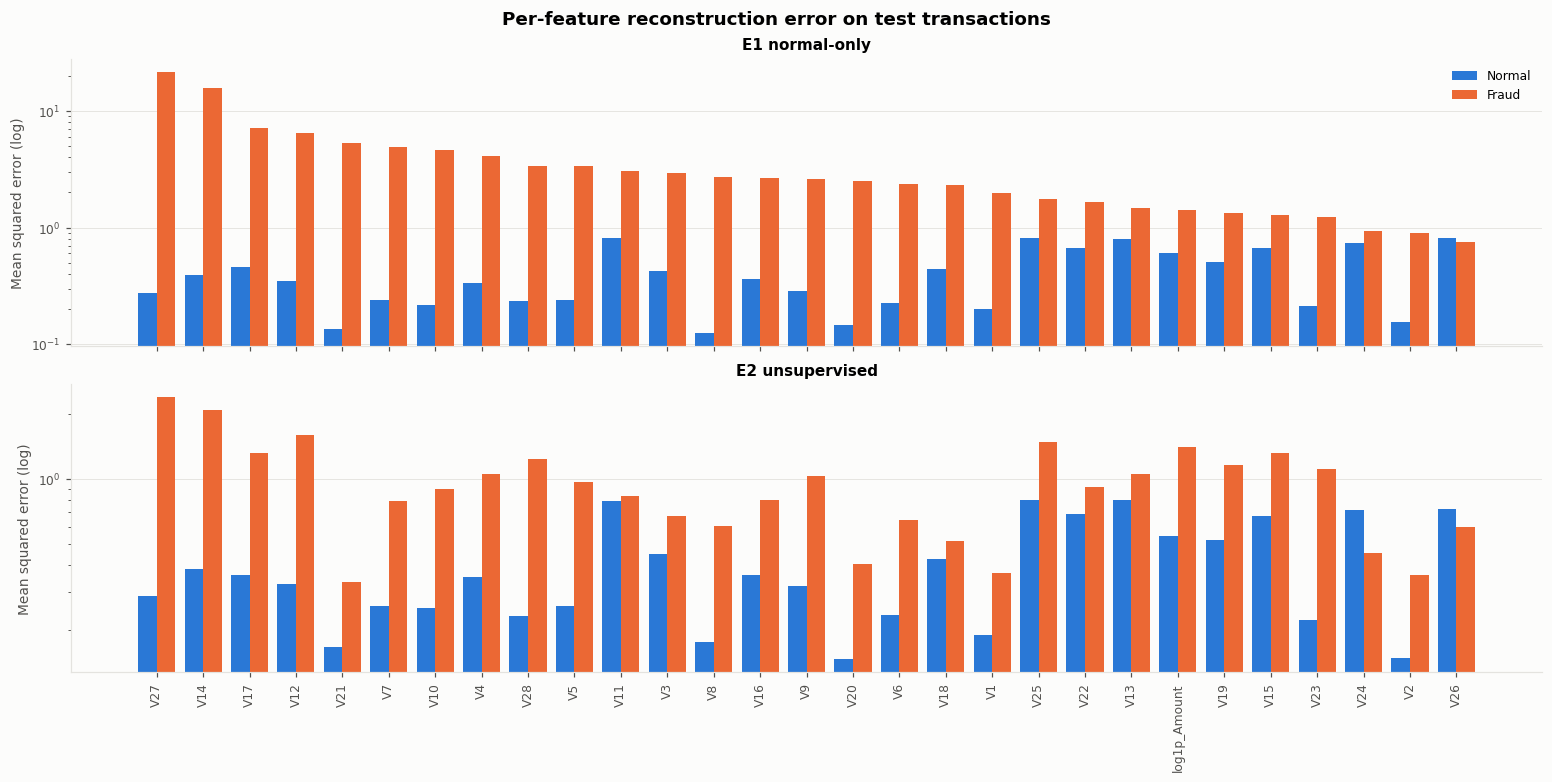

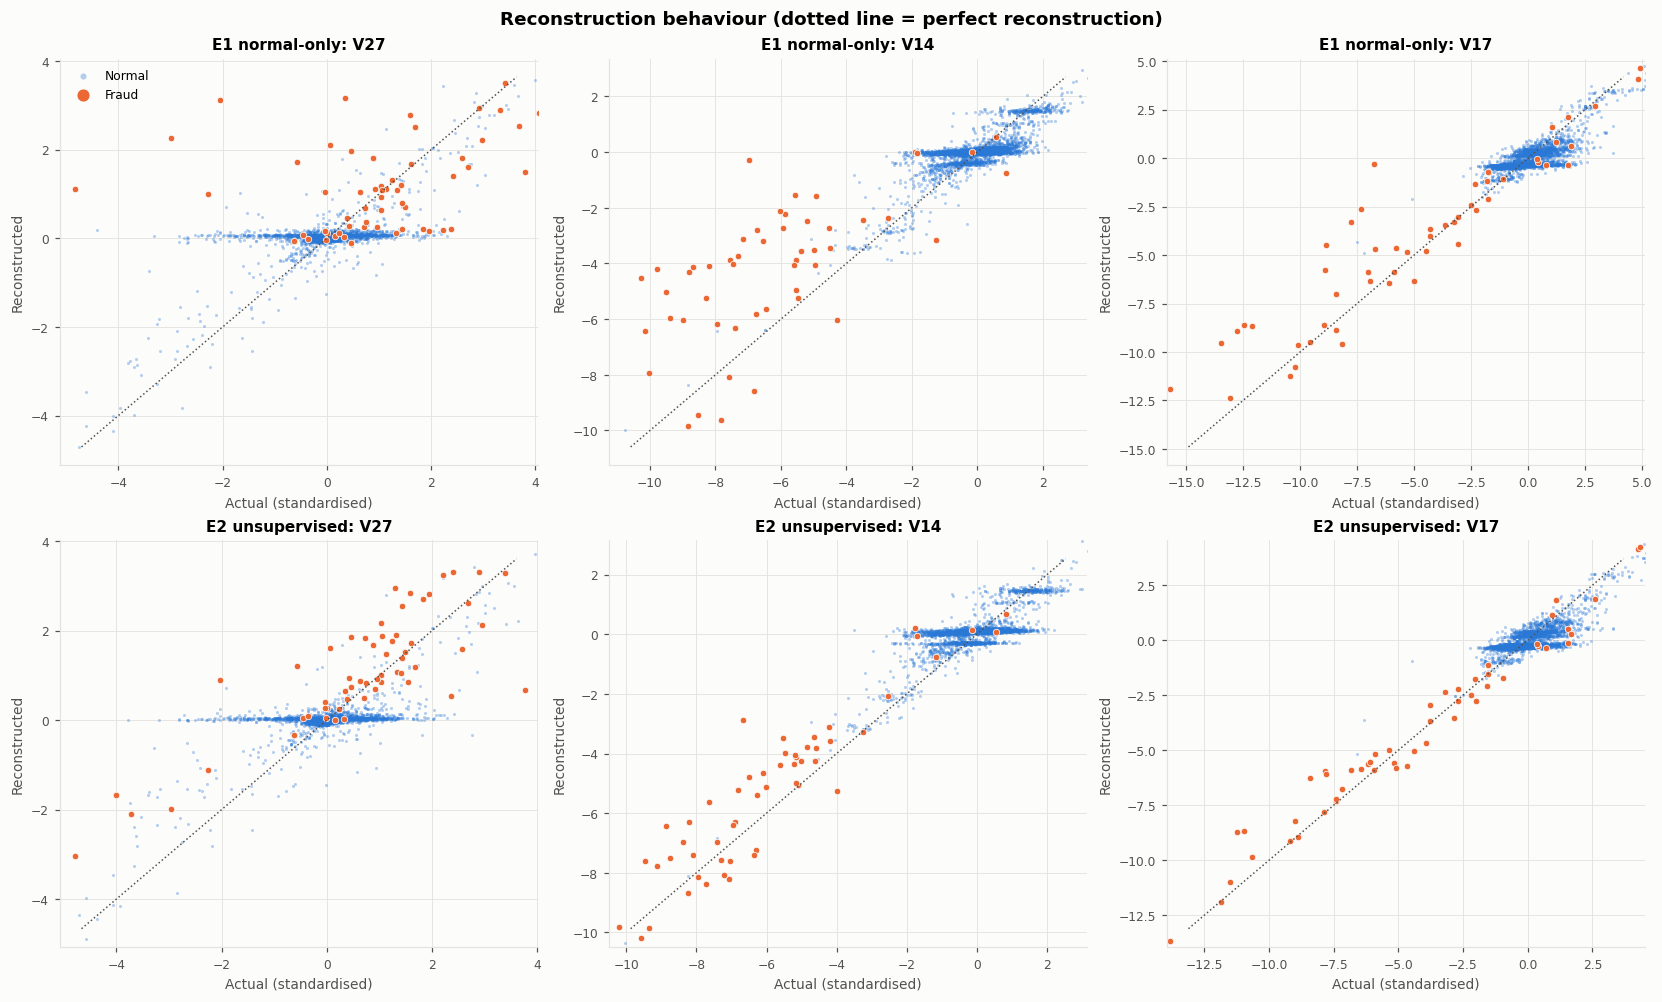

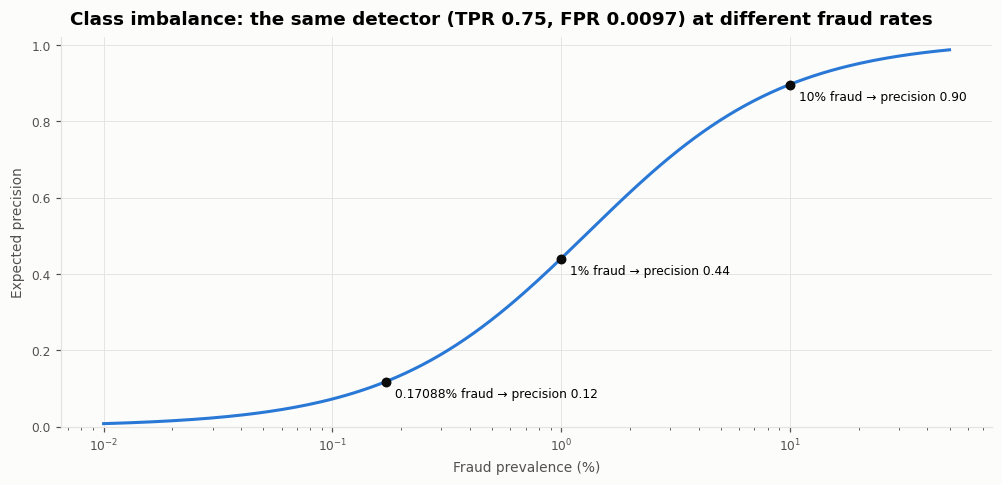

Latent summary: {'e1': {'median_norm_normal': 1.46, 'median_norm_fraud': 4.93, 'centroid_distance': 4.69}, 'e2': {'median_norm_normal': 1.36, 'median_norm_fraud': 4.52, 'centroid_distance': 3.86}}


In [29]:
@torch.no_grad()
def reconstruct(model, X):
    return np.concatenate([model(torch.from_numpy(np.ascontiguousarray(X[s:s + 8192])).to(DEVICE), sample=False)[0].cpu().numpy() for s in range(0, len(X), 8192)])

REC = {e: reconstruct(RUNS[e][hs]["model"], DATA[e]["X_test"]) for e in RUNS}
FEATURE_ERRORS = {e: pd.DataFrame({"normal": ((DATA[e]["X_test"] - REC[e]) ** 2)[Y_TEST == 0].mean(0),
                                   "fraud": ((DATA[e]["X_test"] - REC[e]) ** 2)[Y_TEST == 1].mean(0)}, index=MODEL_FEATURES) for e in RUNS}
order_f = FEATURE_ERRORS["e1"].sort_values("fraud", ascending=False).index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout="constrained")
for ax, e in zip(axes, RUNS):
    t = FEATURE_ERRORS[e].reindex(order_f); x = np.arange(29)
    ax.bar(x - 0.2, t.normal, width=0.4, color=NORMAL_C, label="Normal"); ax.bar(x + 0.2, t.fraud, width=0.4, color=FRAUD_C, label="Fraud")
    ax.set_yscale("log"); ax.set_title(LABEL[e]); ax.set_ylabel("Mean squared error (log)"); ax.grid(axis="x", visible=False)
axes[0].legend(); axes[1].set_xticks(np.arange(29), order_f, rotation=90)
fig.suptitle("Per-feature reconstruction error on test transactions")
finish(fig, "reconstruction_per_feature")

top3 = [MODEL_FEATURES.index(f) for f in order_f[:3]]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
for row, e in enumerate(RUNS):
    for ax, j in zip(axes[row], top3):
        X_ = DATA[e]["X_test"]; lo, hi = np.percentile(np.r_[X_[normal_idx[:4000], j], X_[fraud_idx, j]], [0.5, 99.5]); pad = 0.05 * (hi - lo)
        ax.plot([lo, hi], [lo, hi], color=TEXT2, linestyle=":", linewidth=1)
        ax.scatter(X_[normal_idx[:4000], j], REC[e][normal_idx[:4000], j], s=4, color=NORMAL_C, alpha=0.35, linewidths=0, label="Normal")
        ax.scatter(X_[fraud_idx, j], REC[e][fraud_idx, j], s=18, color=FRAUD_C, edgecolor=SURFACE, linewidth=0.5, label="Fraud")
        ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad); ax.set_title(f"{LABEL[e]}: {MODEL_FEATURES[j]}")
        ax.set_xlabel("Actual (standardised)"); ax.set_ylabel("Reconstructed")
axes[0, 0].legend(markerscale=2)
fig.suptitle("Reconstruction behaviour (dotted line = perfect reconstruction)")
finish(fig, "reconstruction_scatter")

prev = float(Y_TEST.mean()); grid = np.logspace(-4, np.log10(0.5), 200)
prec = hm["tpr"] * grid / (hm["tpr"] * grid + hm["fpr"] * (1 - grid))
fig, ax = plt.subplots(figsize=(9, 4.3), layout="constrained")
ax.plot(100 * grid, prec, color=NORMAL_C, linewidth=2)
for pv in (prev, 0.01, 0.1):
    v = hm["tpr"] * pv / (hm["tpr"] * pv + hm["fpr"] * (1 - pv))
    ax.scatter([100 * pv], [v], color=TEXT, s=30, zorder=3); ax.annotate(f"{100 * pv:g}% fraud → precision {v:.2f}", (100 * pv, v), xytext=(6, -10), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Fraud prevalence (%)"); ax.set_ylabel("Expected precision"); ax.set_ylim(0, 1.02)
fig.suptitle(f"Class imbalance: the same detector (TPR {hm['tpr']:.2f}, FPR {hm['fpr']:.4f}) at different fraud rates")
finish(fig, "class_imbalance_effect")
print("Latent summary:", {e: {k: round(v, 2) for k, v in d.items()} for e, d in LATENT.items()})

## 21. Results and discussion
The text below is generated from the metrics computed in this run, so it always matches the saved outputs.

In [30]:
e1, e2 = PER_SEED[PER_SEED.experiment == "e1"], PER_SEED[PER_SEED.experiment == "e2"]
f = lambda s, k: f"{s[k].mean():.3f} ± {s[k].std():.3f}"
best_seed = int(e1.loc[e1.average_precision.idxmax(), "seed"])
qm, qn, qr = QUALITY["decoder_mean"], QUALITY["decoder_mean_plus_noise"], QUALITY["real_vs_real_reference"]
fp_per_tp = hm["fp"] / max(hm["tp"], 1)
RESULTS_MD = f"""
### Anomaly detection (test set: {int((Y_TEST == 0).sum()):,} normal, {int(Y_TEST.sum())} fraud)

| | E1 normal-only (primary) | E2 unsupervised |
|---|---|---|
| PR-AUC (average precision) | **{f(e1, 'average_precision')}** | {f(e2, 'average_precision')} |
| ROC-AUC | {f(e1, 'roc_auc')} | {f(e2, 'roc_auc')} |
| Precision at τ | {f(e1, 'precision')} | {f(e2, 'precision')} |
| Recall at τ | {f(e1, 'recall')} | {f(e2, 'recall')} |
| F1 at τ | {f(e1, 'f1')} | {f(e2, 'f1')} |
| False-positive rate | {f(e1, 'fpr')} | {f(e2, 'fpr')} |

**E1 performance.**
- **Overall:** the one-class VAE detects fraud without ever seeing a fraud label. Its PR-AUC of {e1.average_precision.mean():.3f} is about {e1.average_precision.mean() / prev:.0f}× the random baseline ({prev:.4f}).
- **Threshold:** the validation-calibrated τ gives a test false-positive rate of {e1.fpr.mean():.4f}, close to the 1% target, so the label-free calibration transfers to unseen data.
- **Headline seed {hs}:** {hm['tp']} of {int(Y_TEST.sum())} frauds caught and {hm['fp']} false alarms (precision {hm['precision']:.3f}, 95% CI {CI['precision'][0]:.3f}–{CI['precision'][1]:.3f}; recall {hm['recall']:.3f}, CI {CI['recall'][0]:.3f}–{CI['recall'][1]:.3f}). The best seed by AP is seed {best_seed}, and the 5-seed mean is the representative figure.
- **Precision is low** because of class imbalance. Even at a {100 * hm['fpr']:.2f}% false-positive rate there are about {fp_per_tp:.1f} false alarms per fraud caught. At a 1% or 10% fraud rate, the same detector would reach precision of about {hm['tpr'] * 0.01 / (hm['tpr'] * 0.01 + hm['fpr'] * 0.99):.2f} and {hm['tpr'] * 0.1 / (hm['tpr'] * 0.1 + hm['fpr'] * 0.9):.2f} (see the class-imbalance figure).

**Contamination (E2).**
- **The gap:** training on all rows lowers PR-AUC from {e1.average_precision.mean():.3f} to {e2.average_precision.mean():.3f}; E1 is better in {int((e1.average_precision.to_numpy() > e2.average_precision.to_numpy()).sum())} of 5 seeds (paired bootstrap ΔAP {PAIRED['observed']:.3f}, 95% CI {PAIRED['ci_low']:.3f}–{PAIRED['ci_high']:.3f}).
- **The cause:** the training frauds are {100 * y_tr2.mean():.2f}% of rows but {100 * FRAUD_SQ_SHARE:.1f}% of the squared feature magnitude, so squared-error training spends capacity on reconstructing them. Frauds also resemble each other, so this carries over to unseen frauds: the median test-fraud error falls from {FRAUD_MEDIAN['e1']:.2f} (E1) to {FRAUD_MEDIAN['e2']:.2f} (E2), and the fraud/normal error ratio falls from {SEPARATION['e1']:.1f}× to {SEPARATION['e2']:.1f}×.
- **The latent space still separates frauds:** centroid distance {LATENT['e1']['centroid_distance']:.2f} for E1 and {LATENT['e2']['centroid_distance']:.2f} for E2. Contamination mainly damages the *reconstruction* score, which is why E2's ELBO-based score (AP {e2.ap_neg_elbo.mean():.3f}) beats its reconstruction score.

**Reconstruction and anomaly scores.**
- **What the score measures:** reconstruction error shows how far a transaction is from what the model learned as normal. Frauds that look structurally normal are missed, and rare legitimate transactions raise false alarms. A high score is **not** a fraud probability.
- **Secondary scores:** the negative ELBO (AP {e1.ap_neg_elbo.mean():.3f}) and the importance-weighted −log p(x) (AP {e1.ap_iwae_nll.mean():.3f}) rank transactions similarly.

### Synthetic data (E1 seed {hs}, {N_SYNTH:,} rows per sampler)

| | Decoder mean (primary) | + fitted noise (variant) | Real vs real |
|---|---|---|---|
| Mean KS | {qm['mean_ks']:.3f} | {qn['mean_ks']:.3f} | {qr['mean_ks']:.3f} |
| Std ratio (V features) | {qm['std_ratio_V']:.2f} | {qn['std_ratio_V']:.2f} | {qr['std_ratio_V']:.2f} |
| Correlation difference (Frobenius) | {qm['corr_frobenius_diff']:.2f} | {qn['corr_frobenius_diff']:.2f} | {qr['corr_frobenius_diff']:.2f} |
| Amount–V2 correlation (real {qm['amount_v2_corr_real']:.2f}) | {qm['amount_v2_corr_synth']:.2f} | {qn['amount_v2_corr_synth']:.2f} | {qr['amount_v2_corr_synth']:.2f} |
| Classifier two-sample AUC, logistic / boosting | {qm['c2st_logistic']:.2f} / {qm['c2st_gradient_boosting']:.2f} | {qn['c2st_logistic']:.2f} / {qn['c2st_gradient_boosting']:.2f} | {qr['c2st_logistic']:.2f} / {qr['c2st_gradient_boosting']:.2f} |
| Exact copies of training rows | {qm['exact_copies_of_training_rows']} | {qn['exact_copies_of_training_rows']} | — |

**Assessment:**
- **Validity:** all samples are valid ({qm['valid_pct']:.0f}%) and none copies a training row.
- **Primary sampler:** decoder-mean samples match the centre and the main Amount relationships, but they are too smooth (about {100 * qm['std_ratio_V']:.0f}% of the real spread).
- **Noise variant:** adding fitted noise brings per-feature distributions much closer, at the cost of diluting dependencies.
- **Detectability:** a non-linear classifier still separates both samplers from real data, so the VAE captures first-order structure but not the full joint distribution.
- **Interpretability:** samples live in the anonymised PCA feature space and are not interpretable transactions.
"""
(OUT / "results_summary.md").write_text(RESULTS_MD)
display(Markdown(RESULTS_MD))


### Anomaly detection (test set: 42,647 normal, 73 fraud)

| | E1 normal-only (primary) | E2 unsupervised |
|---|---|---|
| PR-AUC (average precision) | **0.432 ± 0.047** | 0.038 ± 0.016 |
| ROC-AUC | 0.947 ± 0.016 | 0.863 ± 0.016 |
| Precision at τ | 0.104 ± 0.013 | 0.042 ± 0.003 |
| Recall at τ | 0.652 ± 0.072 | 0.263 ± 0.025 |
| F1 at τ | 0.179 ± 0.021 | 0.073 ± 0.006 |
| False-positive rate | 0.010 ± 0.001 | 0.010 ± 0.001 |

**E1 performance.**
- **Overall:** the one-class VAE detects fraud without ever seeing a fraud label. Its PR-AUC of 0.432 is about 253× the random baseline (0.0017).
- **Threshold:** the validation-calibrated τ gives a test false-positive rate of 0.0097, close to the 1% target, so the label-free calibration transfers to unseen data.
- **Headline seed 0:** 55 of 73 frauds caught and 413 false alarms (precision 0.118, 95% CI 0.100–0.134; recall 0.753, CI 0.644–0.849). The best seed by AP is seed 0, and the 5-seed mean is the representative figure.
- **Precision is low** because of class imbalance. Even at a 0.97% false-positive rate there are about 7.5 false alarms per fraud caught. At a 1% or 10% fraud rate, the same detector would reach precision of about 0.44 and 0.90 (see the class-imbalance figure).

**Contamination (E2).**
- **The gap:** training on all rows lowers PR-AUC from 0.432 to 0.038; E1 is better in 5 of 5 seeds (paired bootstrap ΔAP 0.462, 95% CI 0.351–0.575).
- **The cause:** the training frauds are 0.17% of rows but 4.1% of the squared feature magnitude, so squared-error training spends capacity on reconstructing them. Frauds also resemble each other, so this carries over to unseen frauds: the median test-fraud error falls from 2.08 (E1) to 0.86 (E2), and the fraud/normal error ratio falls from 5.7× to 2.5×.
- **The latent space still separates frauds:** centroid distance 4.69 for E1 and 3.86 for E2. Contamination mainly damages the *reconstruction* score, which is why E2's ELBO-based score (AP 0.117) beats its reconstruction score.

**Reconstruction and anomaly scores.**
- **What the score measures:** reconstruction error shows how far a transaction is from what the model learned as normal. Frauds that look structurally normal are missed, and rare legitimate transactions raise false alarms. A high score is **not** a fraud probability.
- **Secondary scores:** the negative ELBO (AP 0.450) and the importance-weighted −log p(x) (AP 0.420) rank transactions similarly.

### Synthetic data (E1 seed 0, 42,647 rows per sampler)

| | Decoder mean (primary) | + fitted noise (variant) | Real vs real |
|---|---|---|---|
| Mean KS | 0.221 | 0.053 | 0.006 |
| Std ratio (V features) | 0.50 | 0.85 | 1.00 |
| Correlation difference (Frobenius) | 3.73 | 1.69 | 0.66 |
| Amount–V2 correlation (real -0.55) | -0.56 | -0.17 | -0.55 |
| Classifier two-sample AUC, logistic / boosting | 0.77 / 1.00 | 0.55 / 0.99 | 0.50 / 0.50 |
| Exact copies of training rows | 0 | 0 | — |

**Assessment:**
- **Validity:** all samples are valid (100%) and none copies a training row.
- **Primary sampler:** decoder-mean samples match the centre and the main Amount relationships, but they are too smooth (about 50% of the real spread).
- **Noise variant:** adding fitted noise brings per-feature distributions much closer, at the cost of diluting dependencies.
- **Detectability:** a non-linear classifier still separates both samplers from real data, so the VAE captures first-order structure but not the full joint distribution.
- **Interpretability:** samples live in the anonymised PCA feature space and are not interpretable transactions.


## 22. Limitations and future work

**Dataset limitations:**
- **Age and span:** the transactions are from **September 2013 and cover only two days**. Fraud patterns, payment technology and customer behaviour have changed since, so results **cannot automatically be generalised to contemporary banking systems**.
- **Anonymised features:** `V1–V28` are **anonymised PCA components**. Their meaning is unknown, and the providers fitted the PCA on all rows, including our test rows. Domain interpretation and semantic validation are impossible.
- **Few frauds:** only about 70 frauds per evaluation split, so metrics have wide confidence intervals and differences between seeds are within noise.
- **No context:** there are no customer, merchant or sequence features, so behavioural patterns over time cannot be modelled.

**Method and architecture limitations:**
- **Reconstruction error is not a fraud probability,** and it does **not guarantee that every fraudulent transaction will be detected**. Frauds that resemble normal transactions are missed.
- **The primary setup is one-class / semi-supervised:** labels select the normal training rows. It is **not** strictly fully unsupervised. The truly unsupervised variant (E2) performs far worse because of contamination.
- **Precision is limited by the very low fraud rate:** about 1% false positives still outnumbers the frauds.
- **Generator limits:** a Gaussian decoder with unit variance gives smooth samples with thin tails, and a single 8-dimensional latent space cannot capture the full non-linear joint structure.
- **Synthetic samples** exist only in the anonymised feature space, carry no labels, and should not be presented as real or verified transactions.
- **Fixed design:** hyperparameters were fixed in advance rather than tuned; the latent size, β and architecture were not explored in this notebook.

**Future work:**
- **Scores:** combine latent and reconstruction signals (KL term, latent density, ELBO), since contamination hurt reconstruction more than latent separation.
- **Robustness to contamination:** robust training (trimmed or Huber-type losses, iterative removal of high-error training rows) so that unlabelled data can be used safely.
- **Generator:** richer decoders (learned per-feature variance, heavy-tailed likelihoods, normalising-flow priors, β-VAE / VQ-VAE variants) for sharper synthetic data, plus conditional VAEs to study fraud-like generation responsibly.
- **Sensitivity:** analyses over latent size, β, scaler and a deterministic-autoencoder baseline, plus time-ordered splits for drift.
- **Data:** validation on newer and richer datasets, with interpretable features and longer time spans.

## 23. End-to-end verification, export and download

The checks below confirm the integrity requirements programmatically. All outputs are then bundled into `vae_outputs.zip`, which downloads automatically on Colab.

In [31]:
def png_ok(p: Path) -> bool:
    return p.is_file() and p.stat().st_size > 1000 and p.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n"

checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": detail})

check("partition_counts", partition_table.loc[["train", "val", "test"], "rows"].sum() == len(df) == CONFIG["dataset"]["rows"],
      "; ".join(f"{s}: {int(partition_table.loc[s, 'rows']):,} ({int(partition_table.loc[s, 'fraud'])} fraud)" for s in ("train", "val", "test")))
check("class_never_a_model_input", "Class" not in MODEL_FEATURES and all(DATA[e][k].shape[1] == 29 for e in DATA for k in DATA[e]), "29 inputs: V1-V28 + log1p(Amount)")
check("primary_model_trained_on_normal_only", y_all[PARTS["e1_train"]].sum() == 0 and len(DATA["e1"]["X_train"]) == len(PARTS["e1_train"]), f"{len(PARTS['e1_train']):,} normal rows")
check("threshold_calibration_without_fraud_labels", y_all[PARTS["e1_val"]].sum() == 0 and THRESHOLD_RECORD["fraud_labels_used"] is False,
      "E1: normal validation rows; E2: all validation rows, unlabelled")
ev = [e["event"] for e in VAULT.events]
check("test_labels_only_after_predictions_saved",
      ev.index("e1: test predictions saved (predictions_e1_all_seeds.csv)") < ev.index("e1: test labels revealed")
      and ev.index("e2: test predictions saved (predictions_e2_all_seeds.csv)") < ev.index("e2: test labels revealed"), " → ".join(ev))
_g = torch.Generator().manual_seed(GEN["seed"])
with torch.no_grad():
    _direct = gen_model.decode(torch.randn((5, 8), generator=_g).to(DEVICE)).double().cpu().numpy()
check("synthetic_samples_come_from_the_decoder", np.allclose(_direct, generate(gen_model, 5, GEN["seed"])), "decode(z ~ N(0, I)) reproduces the exported generator")
expected_figs = ["eda_overview", "training_curves_e1_seed0", "threshold_calibration_e1", "synthetic_distributions_decoder_mean", "synthetic_pca",
                 "test_pr_roc_confusion_e1", "test_score_distributions_e1", "threshold_sensitivity_e1", "comparison_e1_vs_e2", "latent_space_e1_vs_e2",
                 "reconstruction_per_feature", "class_imbalance_effect"]
check("required_plots_exist_and_are_valid_png", all(png_ok(DIRS["figures"] / f"{n}.png") for n in expected_figs), f"{len(FIGURES)} figures saved")
syn = pd.read_csv(SYNTHETIC["decoder_mean"]["path"])
check("synthetic_csv_valid", list(syn.columns) == RAW_INPUT_COLUMNS and "Class" not in syn.columns and len(syn) == N_SYNTH and np.isfinite(syn.to_numpy()).all(),
      f"{len(syn):,} rows, columns V1-V28 + Amount, no label")
ck = torch.load(RUNS["e1"][hs]["checkpoint"], map_location=DEVICE, weights_only=True)
reloaded = VAE(VAEConfig(**ck["model_config"])).to(DEVICE); reloaded.load_state_dict(ck["model_state"])
check("checkpoint_reloads_and_reproduces_scores", np.allclose(recon_mse(reloaded, DATA["e1"]["X_test"]), s1), Path(RUNS["e1"][hs]["checkpoint"]).name)
saved = pd.read_csv(DIRS["metrics"] / "detection_metrics_per_seed.csv")
check("reported_metrics_match_saved_files", np.allclose(saved[METRIC_COLS].to_numpy(), PER_SEED[METRIC_COLS].to_numpy())
      and abs(saved.query("experiment == 'e1'").average_precision.mean() - e1.average_precision.mean()) < 1e-12, "detection_metrics_per_seed.csv")
VERIFICATION = pd.DataFrame(checks)
VERIFICATION.to_csv(DIRS["metrics"] / "verification_checks.csv", index=False)
assert VERIFICATION.passed.all(), VERIFICATION[~VERIFICATION.passed]
VERIFICATION

,check,passed,detail
0,partition_counts,True,"train: 199,366 (345 fraud); val: 42,721 (74 fr..."
1,class_never_a_model_input,True,29 inputs: V1-V28 + log1p(Amount)
2,primary_model_trained_on_normal_only,True,"199,021 normal rows"
3,threshold_calibration_without_fraud_labels,True,E1: normal validation rows; E2: all validation...
4,test_labels_only_after_predictions_saved,True,split created; test labels locked → e1: test p...
5,synthetic_samples_come_from_the_decoder,True,"decode(z ~ N(0, I)) reproduces the exported ge..."
6,required_plots_exist_and_are_valid_png,True,20 figures saved
7,synthetic_csv_valid,True,"42,647 rows, columns V1-V28 + Amount, no label"
8,checkpoint_reloads_and_reproduces_scores,True,vae_e1_seed0.pt
9,reported_metrics_match_saved_files,True,detection_metrics_per_seed.csv


In [32]:
RUNTIME_MIN = (time.perf_counter() - NOTEBOOK_START) / 60
EXECUTION_REPORT = {
    "completed_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "runtime_minutes": round(RUNTIME_MIN, 1),
    "environment": ENVIRONMENT, "seeds": {"split": CONFIG["split"]["seed"], "models": CONFIG["seeds"], "validation_noise": CONFIG["training"]["val_noise_seed"],
                                          "scores": CONFIG["scores"]["seed"], "bootstrap": CONFIG["evaluation"]["bootstrap_seed"], "generation": GEN["seed"]},
    "dataset_sha256": DATASET_VERIFICATION["sha256"], "dataset_checks": DATASET_VERIFICATION["checks"],
    "partition_counts": partition_table[["rows", "normal", "fraud"]].to_dict(orient="index"),
    "verification_checks": VERIFICATION.to_dict(orient="records"), "label_access_log": VAULT.events,
    "headline": {"e1_mean_average_precision": float(e1.average_precision.mean()), "e2_mean_average_precision": float(e2.average_precision.mean())},
}
save_json(EXECUTION_REPORT, OUT / "execution_report.json")

zip_path = Path("vae_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            zf.write(p, p.as_posix())
with zipfile.ZipFile(zip_path) as zf:
    assert zf.testzip() is None
    n_files = len(zf.namelist())
print(f"Bundled {n_files} files into {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB); notebook runtime {RUNTIME_MIN:.1f} min")
inventory = pd.DataFrame([{"file": p.relative_to(OUT).as_posix(), "kB": round(p.stat().st_size / 1e3, 1)} for p in sorted(OUT.rglob("*")) if p.is_file()])
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))
inventory.groupby(inventory.file.str.split("/").str[0]).agg(files=("file", "size"), total_kB=("kB", "sum"))

Bundled 74 files into vae_outputs.zip (22.3 MB); notebook runtime 12.1 min


,files,total_kB
file,,
checkpoints,12,414.8
config.json,1,1.4
environment.json,1,0.4
execution_report.json,1,4.1
figures,20,2284.5
metrics,23,250.0
predictions,12,24529.2
results_summary.md,1,3.6
synthetic,3,23538.6


**Outputs in `vae_outputs/` (also in `vae_outputs.zip`):**
- **`checkpoints/`:** trained E1 (primary) and E2 (secondary) VAE checkpoints for every seed, plus the fitted transformers.
- **`synthetic/`:** synthetic feature-vector CSVs (decoder mean and decoder mean + noise) with metadata.
- **`metrics/`:** detection metrics per seed and summary, headline metrics with confidence intervals, threshold sensitivity, E1 vs E2 comparison, synthetic quality, training histories, partition counts, leakage and verification checks.
- **`predictions/`:** test predictions, saved before labels were revealed.
- **`figures/`:** all plots.
- **Top level:** `results_summary.md`, `execution_report.json`, `config.json` and `environment.json`.